<img src="https://images.seeklogo.com/logo-png/28/1/u-cayetano-heredia-logo-png_seeklogo-289967.png" alt="LOGO UPCH" width=250 align="right">

<br>
<h1><font color="#7F000E" size=5>UNIVERSIDAD PERUANA CAYETANO HEREDIA</font></h1>
<h1><font color="#7F000E" size=6>SEÑALES BIOMÉDICAS</font></h1>
<h1><font color="#7F000E" size=4>LAB 11 — Tratamiento de la señal ECG: detección de latidos y extracción de características para clasificación</font></h1>
<br>
<br>
<div style="text-align:right">
<font color="#7F000E" size=3> Curso: Introducción a las Señales Biomédicas</font><br>
<font color="#7F000E" size=3> Modalidad: Google Colab</font><br>
<font color="#7F000E" size=3> Equipo: BITalino (r)evolution — sensor ECG</font><br>
<font color="#7F000E" size=3> Duración: 1 hora</font><br>
</div>

| Campo | Completar |
|---|---|
| **Nombre del estudiante** | Jairo Villalobos |
| **Código** | ✍️ |
| **Grupo** | 11 |
| **Fecha** | 30/10/2026 |

> **Artículo base:** T. Subba y T. Chingtham, *"Comparative Analysis of Machine Learning Algorithms With Advanced Feature Extraction for ECG Signal Classification"*, **IEEE Access**, 2024. DOI: [10.1109/ACCESS.2024.3387041](https://doi.org/10.1109/ACCESS.2024.3387041)

<a id="indice"></a>
# 📑 Índice de contenido

> 💡 En Colab también puedes navegar con el panel **"Índice"** (ícono ☰ de la barra izquierda).

**[Introducción](#intro)**
- ¿Qué haremos hoy? · Definición fácil · Nuestros datos · Agenda

**[⚙️ Configuración](#config)**

**[🅰️ PARTE A — Conociendo nuestros datos](#parteA)** *(≈ 15 min)*
- [A.1 Subir los archivos e inventario automático](#A1)
- [A.2 Lectura de los registros](#A2)
- [A.3 Primer vistazo: las 12 señales](#A3)
- [A.4 Control de calidad automático](#A4)
- [A.5 Frecuencia cardiaca por condición y derivación](#A5)
- [A.6 Conclusiones de la Parte A y elección de la derivación](#A6)

**[🅱️ PARTE B — Extracción de características y clasificación](#parteB)** *(≈ 40 min)*
- [B.1 Selección de los registros](#B1)
- [B.2 Filtrado](#B2)
- [B.3 Algoritmo de detección de picos R (Pan-Tompkins)](#B3)
- [B.4 Segmentación en latidos](#B4)
- [B.5 Extracción de características (5 familias)](#B5)
- [B.6 La tabla de características](#B6)
- [B.7 Clasificación: comparación de 5 algoritmos](#B7)
- [B.8 Conclusiones de la Parte B](#B8)

**[📝 Cuestionario final: experimenta con tus datos](#cuestionario)** *(≈ 5 min o como tarea)*

**[📦 Entregables y referencias](#entregables)**

<a id="intro"></a>
# Introducción

## 🎯 ¿Qué haremos hoy?

**Objetivo: extraer características de la señal ECG para clasificar latidos según la condición fisiológica en que fueron registrados.**

Seguiremos el flujo del artículo base, que describe cada latido con características **morfológicas, estadísticas, espectrales y wavelet** y compara cinco algoritmos de *machine learning*. La diferencia es que trabajaremos con **nuestros propios registros** del laboratorio de ECG.

**ARTICULO: Análisis Comparativo de Algoritmos de Aprendizaje Automático con Extracción de Características Avanzada para la Clasificación de Señales de ECG.**

Link: https://www.researchgate.net/publication/379739044_Comparative_Analysis_of_Machine_Learning_Algorithms_with_Advanced_Feature_Extraction_for_ECG_Signal_Classification

### 📖 Definición: ¿qué es "extraer características"?

Imagina que tienes que describir a una persona por teléfono. No envías una foto: dices **su estatura, edad y color de cabello**. Con unos pocos datos, el otro puede reconocerla.

Con un latido pasa lo mismo. Un latido de 600 ms tiene **600 números** (uno por milisegundo): es mucho y muy repetitivo. En lugar de eso, lo describimos con **unos 24 números con significado**: qué tan alto es el pico R, cuánto tardó desde el latido anterior, qué tan "puntiagudo" es, en qué frecuencias tiene su energía...

> **Característica (*feature*)** = un número que resume una propiedad útil de la señal.
>
> **Clasificación** = un algoritmo que aprende, a partir de esos números, a decir a qué grupo pertenece cada latido.

### El flujo completo

```
 PARTE A: conocer los datos                  PARTE B: de la señal a la decisión
 ─────────────────────────                   ─────────────────────────────────────────────────────────────
 Inventario → Vistazo → Calidad → FC   ⇒    Filtrado → Picos R → Latidos → Características → Clasificador
```

## 🫀 Nuestros datos

Cada grupo registró el ECG de un participante con BITalino en **4 condiciones** y **3 derivaciones**, es decir, **12 archivos**:

| Condición | Qué hizo el participante | Duración aprox. |
|---|---|---|
| **Basal** | Reposo, respiración normal | 30 s |
| **Hiperventilación** | Ciclos repetidos de inhalar → mantener → exhalar | 30 s |
| **Hipoventilación** | Retener la respiración el mayor tiempo posible | 30–40 s |
| **Aeróbica** | Registro inmediatamente **después** de ~3 min de ejercicio | 30 s |

**Derivaciones (triángulo de Einthoven).** Los electrodos se colocaron en clavícula/hombro derecho (RA), clavícula/hombro izquierdo (LA) y cresta ilíaca izquierda (LL):

| Derivación | Mide la diferencia entre... |
|---|---|
| **DI** | LA − RA (brazo izquierdo menos brazo derecho) |
| **DII** | LL − RA (pierna izquierda menos brazo derecho) |
| **DIII** | LL − LA (pierna izquierda menos brazo izquierdo) |

> ⚠️ **Dato importante:** con BITalino las derivaciones **no se graban al mismo tiempo**, sino una después de otra, con algunos minutos de diferencia. Esto importará al interpretar los resultados.

**Nombres de archivo esperados:** el cuaderno reconoce automáticamente la condición y la derivación si el nombre contiene `basal`, `hiper`, `hipo` o `aerob` y `D1`, `D2` o `D3`. Ejemplos: `Lectura_basal_D1.txt`, `hiper_D2.txt`, `Hipo_D3.txt`, `Aerobica_D1.txt`. No importan las mayúsculas.

## ⏱️ Agenda (60 min)

| Parte | Contenido | Minutos |
|---|---|---:|
| Configuración | Librerías y carga | 0 – 5 |
| **A** | Conocer los datos: inventario, calidad y frecuencia cardiaca | 5 – 20 |
| **B** | Filtrado → Pan-Tompkins → latidos → características → clasificación | 20 – 55 |
| Cuestionario | Experimentos con tus datos | 55 – 60 (o tarea) |

<a id="config"></a>
# ⚙️ Configuración

| Librería | Para qué la usamos |
|---|---|
| `numpy`, `pandas` | Números y tablas |
| `matplotlib` | Gráficas |
| `scipy.signal` | Filtros y búsqueda de picos |
| `pywt` (PyWavelets) | Transformada wavelet |
| `scikit-learn` | Los cinco clasificadores y la validación |

In [1]:
# PyWavelets no siempre viene en Colab: se instala solo si falta
try:
    import pywt
except ImportError:
    !pip install -q PyWavelets
    import pywt

import os, re, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal
from scipy.stats import skew, kurtosis

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (14, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.titleweight": "bold", "font.size": 11})
np.random.seed(0)

FS_ESPERADA = 1000
ORDEN_CONDICIONES = ["basal", "hiperventilacion", "hipoventilacion", "aerobica"]
COLOR = {"basal": "tab:blue", "hiperventilacion": "tab:orange",
         "hipoventilacion": "tab:purple", "aerobica": "tab:red"}
print("✅ Librerías listas | PyWavelets", pywt.__version__)

✅ Librerías listas | PyWavelets 1.8.0


---
<a id="parteA"></a>
# 🅰️ PARTE A — Conociendo nuestros datos *(≈ 15 min)*

> **Idea central:** antes de extraer características y entrenar modelos, un buen analista **revisa sus datos**. ¿Están todos los archivos? ¿Duran lo suficiente? ¿Hay saturación o artefactos? ¿Tiene sentido fisiológico lo que vemos?
>
> En esta parte usaremos el pipeline del laboratorio como una **"caja negra"** para revisar rápidamente los 12 archivos. En la **Parte B** abriremos esa caja y explicaremos cada paso.

[⬆️ Volver al índice](#indice)

<a id="A1"></a>
## A.1 Subir los archivos e inventario automático

**Paso 1:** ejecuta la celda. En Colab se abrirá un botón para **subir tus 12 archivos `.txt`**; puedes seleccionarlos todos a la vez. Si los archivos ya están en la carpeta, no se pedirá nada.

**Paso 2:** el cuaderno reconoce la **condición** y la **derivación** a partir del nombre de cada archivo y arma un **inventario**.

> Si no hay archivos, se generan **registros de demostración simulados**, solo para que puedas recorrer el cuaderno.

In [2]:
def identificar(nombre):
    # Deduce condición y derivación a partir del nombre del archivo
    n = nombre.lower()
    # En nuestro registro el basal se llamó "reposo" y la aeróbica "act_fisica"
    if "basal" in n or "reposo" in n:       cond = "basal"
    elif "hiper" in n:                      cond = "hiperventilacion"
    elif "hipo" in n:                       cond = "hipoventilacion"
    elif "aerob" in n or "ejercicio" in n or "fisica" in n:  cond = "aerobica"
    else:                                   cond = None
    m = re.search(r"(?:^|[^a-z])d([123])(?:[^0-9]|$)", n)
    deriv = f"D{m.group(1)}" if m else None
    return cond, deriv

def buscar_archivos():
    filas = []
    for ruta in sorted(glob.glob("*.txt")):
        cond, deriv = identificar(os.path.basename(ruta))
        if cond and deriv:
            filas.append({"archivo": ruta, "condicion": cond, "derivacion": deriv})
    return pd.DataFrame(filas, columns=["archivo", "condicion", "derivacion"])

inventario = buscar_archivos()
if len(inventario) == 0:
    try:
        from google.colab import files
        print("📤 Sube tus archivos .txt de OpenSignals (selecciona los 12 a la vez):")
        files.upload()
        inventario = buscar_archivos()
    except ImportError:
        pass

MODO_DEMO = inventario["condicion"].nunique() < 2 if len(inventario) else True
print("Modo:", "⚠️ DEMOSTRACIÓN (datos simulados)" if MODO_DEMO else "✅ datos reales del grupo")

Modo: ✅ datos reales del grupo


In [3]:
# ---- Solo en modo demostración: genera 4 registros simulados (derivación D1) ----
def generar_registro_demo(ruta, fc_media, amp_T, ruido, duracion_s=35, fs=1000, semilla=0):
    rng = np.random.default_rng(semilla)
    n = int(duracion_s * fs); t = np.arange(n) / fs; ecg = np.zeros(n); r_t = 0.5
    while r_t < duracion_s - 0.5:
        rr = 60 / fc_media * (1 + 0.06*np.sin(2*np.pi*0.25*r_t)) + rng.normal(0, 0.04)
        g = rng.normal(1, 0.10)
        for c, a, w in [(-0.16, .12, .025), (-0.03, -.12, .010), (0, 1.0*g, .010),
                        (0.035, -.25*g, .012), (0.30*np.sqrt(rr), amp_T*rng.normal(1, .15), .045)]:
            ecg += a * np.exp(-((t - r_t - c)**2) / (2*w**2))
        r_t += rr
    ecg += 0.10*np.sin(2*np.pi*0.25*t) + 0.02*np.sin(2*np.pi*60*t) + ruido*rng.standard_normal(n)
    adc = np.clip(np.round((ecg/1000*1100/3.3 + 0.5)*1024), 0, 1023).astype(int)
    meta = {"demo": {"sensor": ["ECG"], "column": ["nSeq", "I1", "I2", "O1", "O2", "A2"], "label": ["A2"],
                     "sampling rate": fs, "resolution": [4, 1, 1, 1, 1, 10], "date": "DEMO", "time": "DEMO"}}
    with open(ruta, "w") as f:
        f.write("# OpenSignals Text File Format\n# " + json.dumps(meta) + "\n# EndOfHeader\n")
        f.writelines(f"{i % 16}\t0\t0\t0\t0\t{v}\t\n" for i, v in enumerate(adc))

if MODO_DEMO:
    for i, (cond, fc, aT, rd) in enumerate([("basal", 70, .28, .03), ("hiper", 78, .26, .04),
                                            ("hipo", 62, .30, .04), ("aerobica", 100, .22, .04)]):
        generar_registro_demo(f"DEMO_{cond}_D1.txt", fc, aT, rd, semilla=i)
    inventario = buscar_archivos()

inventario["orden"] = inventario["condicion"].map(ORDEN_CONDICIONES.index)
inventario = inventario.sort_values(["derivacion", "orden"]).drop(columns="orden").reset_index(drop=True)

# Tabla de doble entrada: ¿qué archivo hay para cada condición y derivación?
matriz = inventario.pivot(index="condicion", columns="derivacion", values="archivo").reindex(
    [c for c in ORDEN_CONDICIONES if c in inventario.condicion.values])
print(f"Se encontraron {len(inventario)} archivos:")
display(matriz.fillna("❌ falta"))

Se encontraron 4 archivos:


derivacion,D2
condicion,
basal,d2reposo.txt
hiperventilacion,hiperventilacion_d2.txt
hipoventilacion,hipoventilacion_d2.txt
aerobica,d2_act_fisica.txt


<a id="A2"></a>
## A.2 Lectura de los registros

Un archivo de OpenSignals tiene:
1. Una **cabecera** (líneas con `#`) con un JSON de metadatos: frecuencia de muestreo, resolución, canales, hora de grabación...
2. **Columnas de datos**: `nSeq` (contador de paquetes de 0 a 15), entradas y salidas digitales, y el canal analógico con el ECG (por ejemplo, `A2`).

La función `leer_ecg` lee los metadatos **del propio archivo** y convierte las cuentas del ADC a **milivoltios** con la fórmula del sensor ECG de BITalino:

$$
ECG_{mV} = \frac{\left(\dfrac{ADC}{2^{n}} - \dfrac{1}{2}\right) \cdot V_{CC}}{G_{ECG}} \times 1000, \qquad V_{CC}=3.3\,V,\; G_{ECG}=1100,\; n = 10\ \text{bits}
$$

Además revisa dos cosas de **calidad de adquisición**:
- **Paquetes perdidos:** `nSeq` debe avanzar de 1 en 1. Un salto indica que se perdieron muestras por Bluetooth.
- **Saturación:** muestras pegadas al límite del ADC (0 o ≥ 1022). Ahí la señal real era mayor de lo que el equipo pudo medir.

In [4]:
def formato_hora(texto):
    # "12:4:25.973" -> "12:04:25"
    try:
        return ":".join(f"{int(p):02d}" for p in str(texto).split(".")[0].split(":"))
    except ValueError:
        return str(texto)

def leer_ecg(ruta):
    with open(ruta, "r", encoding="utf-8", errors="ignore") as f:
        cabecera = [f.readline() for _ in range(3)]
    meta = list(json.loads(cabecera[1].lstrip("# ").strip()).values())[0]
    columnas = meta["column"]
    sensores, etiquetas = meta.get("sensor", []), meta.get("label", [])
    # Canal ECG: el que tenga "ECG" en el nombre del sensor; si no, el primer canal analógico
    canal = next((e for s, e in zip(sensores, etiquetas) if "ECG" in s.upper()), etiquetas[0])
    idx = columnas.index(canal)
    n_bits = meta["resolution"][idx]
    datos = pd.read_csv(ruta, sep=r"\s+", comment="#", header=None).iloc[:, :len(columnas)]
    adc = datos.iloc[:, idx].to_numpy(dtype=float)
    nseq = datos.iloc[:, 0].to_numpy(dtype=int)
    return {"ecg_mV": ((adc / 2**n_bits) - 0.5) * 3.3 / 1100 * 1000,
            "fs": int(meta["sampling rate"]), "canal": canal, "sensor": sensores[0] if sensores else "-",
            "hora": formato_hora(meta.get("time", "-")), "bits": n_bits,
            "perdidos": int(np.sum((np.diff(nseq) % 16) != 1)),
            "saturadas": int(np.sum((adc <= 0) | (adc >= 2**n_bits - 2)))}

senales = {}   # aquí guardamos cada registro: senales["Lectura_basal_D1.txt"] = {...}
filas = []
for _, fila in inventario.iterrows():
    r = leer_ecg(fila.archivo)
    senales[fila.archivo] = r
    filas.append({"archivo": fila.archivo, "condición": fila.condicion, "derivación": fila.derivacion,
                  "hora": r["hora"], "duración (s)": round(len(r["ecg_mV"]) / r["fs"], 1),
                  "Fs (Hz)": r["fs"], "bits": r["bits"], "canal": r["canal"], "sensor": r["sensor"],
                  "paquetes perdidos": r["perdidos"], "muestras saturadas": r["saturadas"]})
tabla_lectura = pd.DataFrame(filas)
FS = tabla_lectura["Fs (Hz)"].iloc[0]
assert (tabla_lectura["Fs (Hz)"] == FS).all(), "Todos los archivos deben tener la misma frecuencia de muestreo."
display(tabla_lectura)

,archivo,condición,derivación,hora,duración (s),Fs (Hz),bits,canal,sensor,paquetes perdidos,muestras saturadas
0,d2reposo.txt,basal,D2,14:55:24,31.6,1000,10,A1,ECGBIT,0,476
1,hiperventilacion_d2.txt,hiperventilacion,D2,15:14:50,31.1,1000,10,A1,ECGBIT,0,436
2,hipoventilacion_d2.txt,hipoventilacion,D2,15:05:27,31.4,1000,10,A1,ECGBIT,0,255
3,d2_act_fisica.txt,aerobica,D2,15:30:10,24.1,1000,10,A1,ECGBIT,0,482


### ✍️ Pregunta A.1
1. ¿Cuántos archivos tienes y cuánto dura cada uno? ¿Alguno dura menos de 30 s?
2. ¿Hay paquetes perdidos o muestras saturadas? ¿En qué archivo(s)?
3. Mira la columna **hora**: ¿en qué orden se grabaron las derivaciones de cada condición?

✍️ **Respuesta:**

1. Tenemos 4 archivos, todos de la derivación D2 (no se registraron D1 ni D3). Duraciones: basal (reposo) 31.6 s, hiperventilación 31.1 s, hipoventilación 31.4 s y aeróbica 24.1 s. El registro aeróbico es el único que dura menos de 30 s.
2. No hay paquetes perdidos en ningún archivo (`nSeq` avanza de 1 en 1). Sin embargo, los cuatro archivos tienen muestras saturadas: basal 476, hiperventilación 436, hipoventilación 255 y aeróbica 482. Revisando los valores crudos, la saturación ocurre solo en el límite superior del ADC (1022–1023), es decir, en la punta del pico R. Son unas 10 muestras por latido, así que el equipo "corta" la parte más alta del R en todos los latidos.
3. Como solo hay una derivación, la hora indica el orden de las condiciones: basal (14:55), hipoventilación (15:05), hiperventilación (15:14) y aeróbica (15:30).

<a id="A3"></a>
## A.3 Primer vistazo: las 12 señales

Antes de calcular nada, **miramos**. Graficamos 6 segundos de cada registro: filas = condiciones, columnas = derivaciones. Las señales ya están **filtradas** (0.5–40 Hz + notch 60 Hz) para que se vean limpias; en la Parte B veremos cómo se hace.

> **¿Qué buscar?**
> - ¿El complejo **QRS** (pico grande y estrecho) apunta **hacia arriba o hacia abajo** en cada derivación?
> - ¿Los latidos están **más juntos** en alguna condición?
> - ¿Hay **artefactos**: saltos bruscos, ondas enormes o ruido?

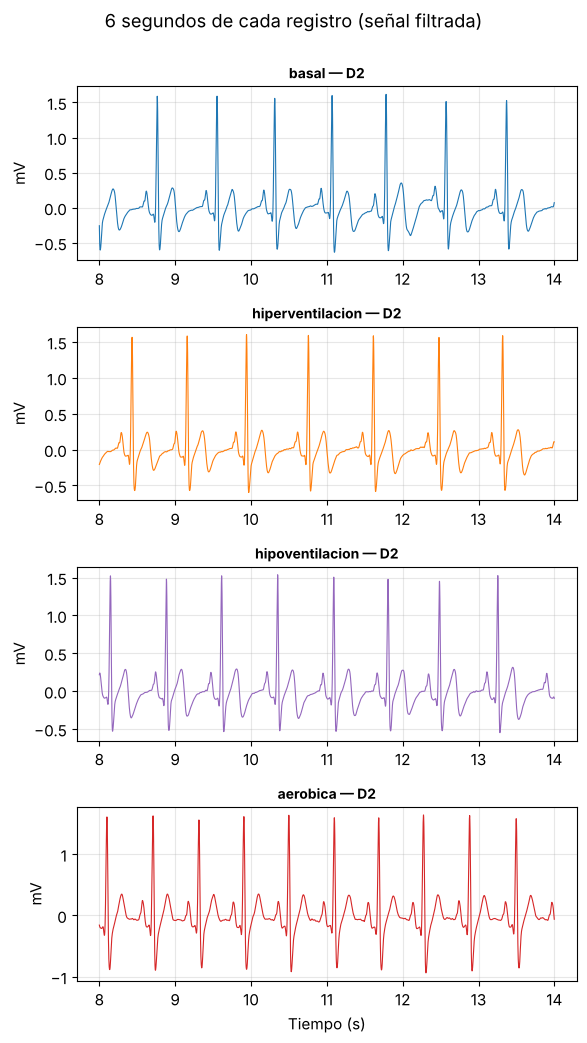

In [5]:
def filtrar_ecg(x, fs=FS):
    # Pasa-banda 0.5–40 Hz + notch 60 Hz (se explica en B.2)
    sos = signal.butter(3, [0.5, 40], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))
    b, a = signal.iirnotch(60, 30, fs=fs)
    return signal.filtfilt(b, a, y)

for r in senales.values():
    r["ecg_f"] = filtrar_ecg(r["ecg_mV"])
    r["t"] = np.arange(len(r["ecg_f"])) / FS

conds = [c for c in ORDEN_CONDICIONES if c in inventario.condicion.values]
derivs = sorted(inventario.derivacion.unique())
T0 = 8   # segundo de inicio de la ventana
fig, ax = plt.subplots(len(conds), len(derivs), figsize=(6*len(derivs), 2.6*len(conds)), squeeze=False)
for i, c in enumerate(conds):
    for j, d in enumerate(derivs):
        a = ax[i, j]
        sel = inventario[(inventario.condicion == c) & (inventario.derivacion == d)]
        if sel.empty:
            a.text(0.5, 0.5, "sin archivo", ha="center", transform=a.transAxes); continue
        r = senales[sel.archivo.iloc[0]]
        sl = (r["t"] >= T0) & (r["t"] < T0 + 6)
        a.plot(r["t"][sl], r["ecg_f"][sl], color=COLOR[c], lw=0.8)
        a.set_title(f"{c} — {d}", fontsize=10)
        if j == 0: a.set_ylabel("mV")
        if i == len(conds) - 1: a.set_xlabel("Tiempo (s)")
plt.suptitle("6 segundos de cada registro (señal filtrada)", y=1.0)
plt.tight_layout(); plt.show()

### ✍️ Pregunta A.2
1. ¿En qué derivación el QRS es claramente **positivo**? ¿En cuál es **negativo** o **bifásico** (sube y baja)?
2. ¿En qué condición se ven los latidos más juntos? ¿Detectas algún artefacto a simple vista?

✍️ **Respuesta:**

1. En D2 el QRS es claramente positivo en las cuatro condiciones (R alto de ~1.5 mV seguido de una S negativa). No tenemos D1 ni D3 para comparar.
2. Los latidos están más juntos en la condición aeróbica (en 6 s se ven 10 latidos, frente a 7–8 en las demás). No se ven artefactos de movimiento ni saltos bruscos; las cuatro señales se ven limpias. Lo único raro es que los picos R tienen casi todos la misma altura (~1.6 mV), lo que coincide con la saturación de la tabla anterior.

<a id="A4"></a>
## A.4 Control de calidad automático

Ahora pasamos **los 12 archivos por el pipeline** del laboratorio. Para cada archivo:

1. **Polaridad:** si el QRS apunta hacia abajo, la señal se **invierte** para que el pico principal sea positivo. Se decide con la **asimetría** (*skewness*): un ECG con picos hacia arriba tiene asimetría positiva.
2. **Detección de picos R** con el algoritmo de Pan-Tompkins (se explica en B.3).
3. **Control de los intervalos RR:** un RR que se aleja más del 35 % de la mediana de sus vecinos es **anómalo**. Suele ser un artefacto detectado como latido o un latido no detectado.
4. **Latidos válidos:** los que tienen ventana completa (−200/+400 ms) y RR normales a ambos lados.

**Semáforo de calidad:**

| Estado | Criterio |
|---|---|
| ✅ Bueno | Sin saturación y sin RR anómalos |
| ⚠️ Revisar | Algunos RR anómalos (< 10 %) |
| ❌ Problemático | Saturación **o** ≥ 10 % de RR anómalos |

In [6]:
def detectar_picos_R(ecg, fs=FS, factor_umbral=0.3, mostrar=False):
    # Algoritmo de Pan-Tompkins simplificado (se explica paso a paso en B.3)
    sos = signal.butter(2, [5, 15], btype="bandpass", fs=fs, output="sos")
    paso1 = signal.sosfiltfilt(sos, ecg)                       # 1. pasa-banda 5–15 Hz
    paso2 = np.gradient(paso1) * fs                            # 2. derivada
    paso3 = paso2**2                                           # 3. cuadrado
    w = int(0.150 * fs)
    paso4 = np.convolve(paso3, np.ones(w) / w, mode="same")    # 4. integración 150 ms
    umbral = factor_umbral * np.percentile(paso4, 99)          # 5. umbral + refractario 250 ms
    jorobas, _ = signal.find_peaks(paso4, height=umbral, distance=int(0.25 * fs))
    v = int(0.1 * fs)                                          # 6. máximo del ECG a ±100 ms
    r = np.unique([max(0, j - v) + np.argmax(ecg[max(0, j - v): j + v]) for j in jorobas])
    return (r, (paso1, paso2, paso3, paso4, umbral)) if mostrar else r

def rr_anomalos(picos, fs=FS, tolerancia=0.35):
    rr = np.diff(picos) / fs
    mediana_local = pd.Series(rr).rolling(9, center=True, min_periods=1).median().to_numpy()
    return rr, np.abs(rr - mediana_local) > tolerancia * mediana_local

def indices_validos(picos, n_muestras, anomalo, fs=FS):
    antes, despues = int(0.2 * fs), int(0.4 * fs)
    return [k for k in range(1, len(picos) - 1)
            if picos[k] - antes >= 0 and picos[k] + despues <= n_muestras
            and not anomalo[k - 1] and not anomalo[k]]

def preparar_registro(r, invertir="auto", factor_umbral=0.3):
    y = r["ecg_f"]
    r["invertida"] = (skew(y) < 0) if invertir == "auto" else bool(invertir)
    r["ecg"] = -y if r["invertida"] else y
    r["picos_R"] = detectar_picos_R(r["ecg"], factor_umbral=factor_umbral)
    r["rr"], r["anomalo"] = rr_anomalos(r["picos_R"])
    r["validos"] = indices_validos(r["picos_R"], len(y), r["anomalo"])
    return r

filas = []
for _, fila in inventario.iterrows():
    r = preparar_registro(senales[fila.archivo])
    pct = 100 * r["anomalo"].mean()
    estado = "❌" if (r["saturadas"] > 0 or pct >= 10) else ("⚠️" if pct > 0 else "✅")
    filas.append({"archivo": fila.archivo, "condición": fila.condicion, "derivación": fila.derivacion,
                  "QRS original": "negativo → invertido" if r["invertida"] else "positivo",
                  "latidos detectados": len(r["picos_R"]), "latidos válidos": len(r["validos"]),
                  "% RR anómalos": round(pct, 1), "saturadas": r["saturadas"],
                  "RR mín (s)": round(r["rr"].min(), 3), "RR máx (s)": round(r["rr"].max(), 3),
                  "estado": estado})
calidad = pd.DataFrame(filas)
display(calidad)

,archivo,condición,derivación,QRS original,latidos detectados,latidos válidos,% RR anómalos,saturadas,RR mín (s),RR máx (s),estado
0,d2reposo.txt,basal,D2,positivo,42,40,0.0,476,0.641,0.834,❌
1,hiperventilacion_d2.txt,hiperventilacion,D2,positivo,40,38,0.0,436,0.681,0.865,❌
2,hipoventilacion_d2.txt,hipoventilacion,D2,positivo,41,39,0.0,255,0.667,0.857,❌
3,d2_act_fisica.txt,aerobica,D2,positivo,39,37,0.0,482,0.562,0.653,❌


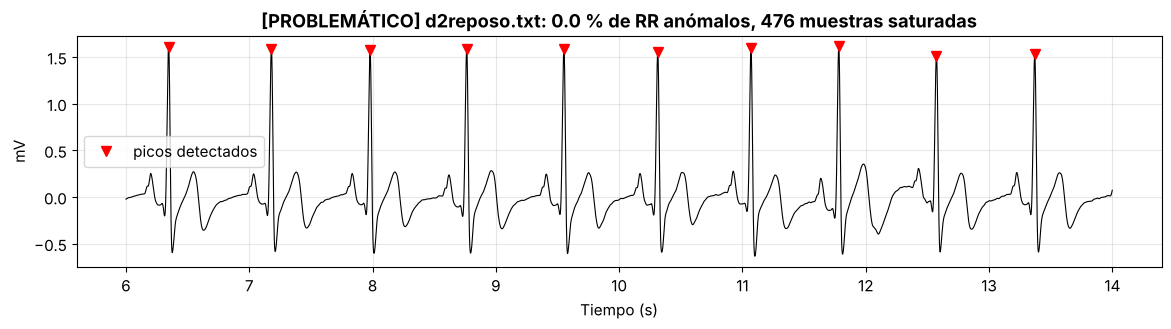

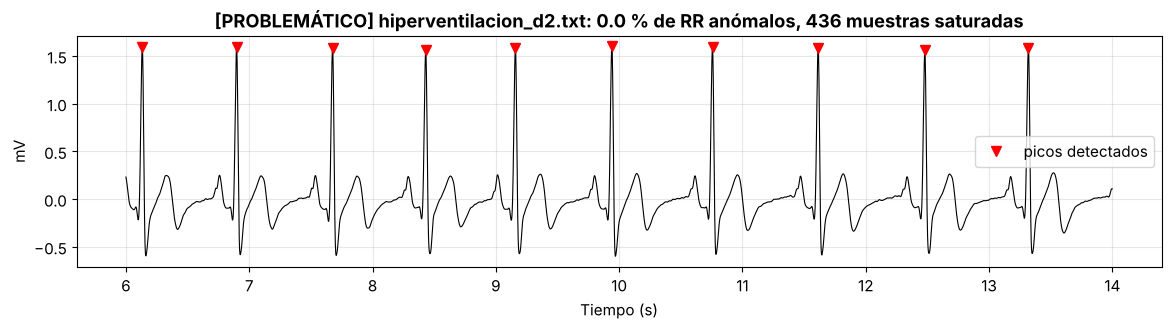

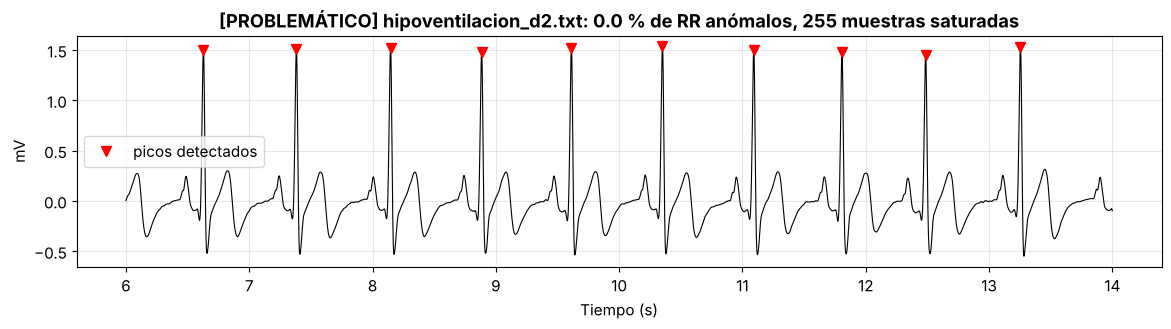

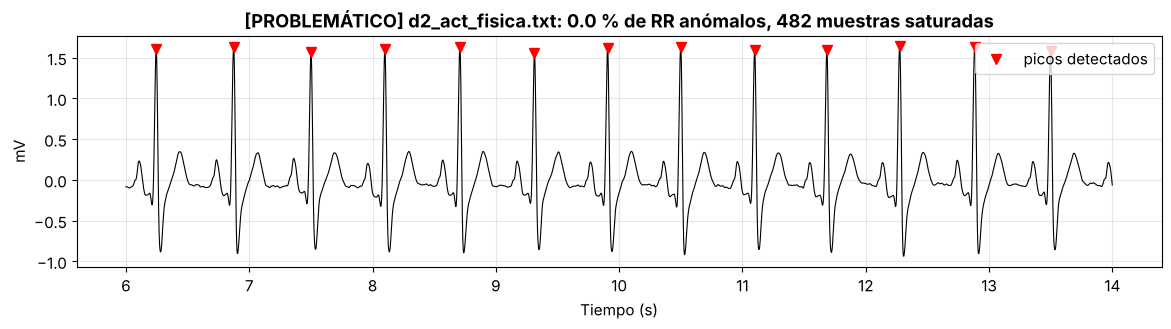

In [7]:
# Zoom a los archivos marcados con ❌ o ⚠️: ¿qué está pasando?
revisar = calidad[calidad.estado != "✅"]
for _, fila in revisar.iterrows():
    r = senales[fila.archivo]
    k_malos = np.flatnonzero(r["anomalo"])
    centro = r["t"][r["picos_R"][k_malos[0]]] if len(k_malos) else 10
    sl = (r["t"] >= max(0, centro - 4)) & (r["t"] < centro + 4)
    p = r["picos_R"][(r["t"][r["picos_R"]] >= max(0, centro - 4)) & (r["t"][r["picos_R"]] < centro + 4)]
    plt.figure(figsize=(14, 3))
    plt.plot(r["t"][sl], r["ecg"][sl], color="black", lw=0.8)
    plt.plot(r["t"][p], r["ecg"][p], "rv", ms=7, label="picos detectados")
    etiqueta = "PROBLEMÁTICO" if fila.estado == "❌" else "REVISAR"
    plt.title(f"[{etiqueta}] {fila.archivo}: {fila['% RR anómalos']} % de RR anómalos, "
              f"{fila.saturadas} muestras saturadas"); plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.legend()
    plt.show()
if revisar.empty:
    print("✅ Todos los archivos pasaron el control de calidad.")

### ✍️ Pregunta A.3
1. ¿Qué archivo(s) quedaron marcados con ❌ o ⚠️? Mirando el zoom, ¿qué tipo de problema tienen (artefacto de movimiento, saturación, latido no detectado)?
2. ¿Qué derivaciones se invirtieron? ¿Coincide con lo que respondiste en la Pregunta A.2?

✍️ **Respuesta:**

1. Los cuatro archivos quedaron con ❌, pero solo por la regla de saturación: ninguno tiene RR anómalos (0 %) y en el zoom todos los picos están bien detectados, sin latidos perdidos ni detecciones sobre ruido. El problema es de adquisición: la ganancia del sensor y la amplitud del R de este participante en D2 hacen que la punta del R pase el rango del ADC. Esto afecta sobre todo a la medida de amplitud R (queda subestimada), pero no a la detección ni a los RR.
2. No se invirtió ninguna derivación (QRS original "positivo" en los cuatro). Coincide con lo de la Pregunta A.2.

<a id="A5"></a>
## A.5 Frecuencia cardiaca por condición y derivación

La **frecuencia cardiaca** se calcula con los intervalos RR: $FC = 60 / RR$ (latidos por minuto, lpm). Calculamos:
- **FC media** de todo el registro.
- **FC al inicio** (primeros 5 latidos) y **al final** (últimos 5 latidos), para ver si cambia durante el registro.

Solo se usan RR **no anómalos**, para que los artefactos no distorsionen el resultado.

derivación,D2
condición,
basal,80.0
hiperventilacion,77.6
hipoventilacion,78.8
aerobica,98.0


,condición,derivación,hora,FC media (lpm),FC inicio,FC final
0,basal,D2,14:55:24,80.0,75.6,83.1
1,hiperventilacion,D2,15:14:50,77.6,76.5,83.8
2,hipoventilacion,D2,15:05:27,78.8,83.7,78.7
3,aerobica,D2,15:30:10,98.0,104.0,94.5


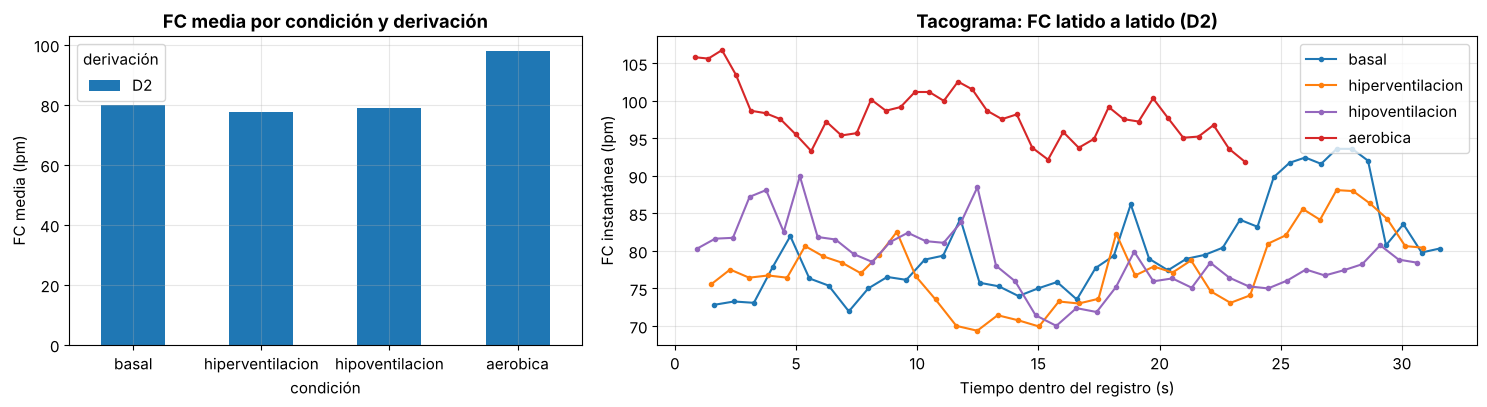

In [8]:
filas = []
for _, fila in inventario.iterrows():
    r = senales[fila.archivo]
    rr_ok = r["rr"][~r["anomalo"]]
    filas.append({"condición": fila.condicion, "derivación": fila.derivacion, "hora": senales[fila.archivo]["hora"],
                  "FC media (lpm)": round(60 / rr_ok.mean(), 1),
                  "FC inicio": round(60 / rr_ok[:5].mean(), 1), "FC final": round(60 / rr_ok[-5:].mean(), 1)})
fc = pd.DataFrame(filas)
display(fc.pivot(index="condición", columns="derivación", values="FC media (lpm)").reindex(conds))
display(fc)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
fc.pivot(index="condición", columns="derivación", values="FC media (lpm)").reindex(conds).plot.bar(ax=ax[0], rot=0)
ax[0].set_ylabel("FC media (lpm)"); ax[0].set_title("FC media por condición y derivación")
d_ref = derivs[0]
for c in conds:
    sel = inventario[(inventario.condicion == c) & (inventario.derivacion == d_ref)]
    if sel.empty: continue
    r = senales[sel.archivo.iloc[0]]
    ok = ~r["anomalo"]
    ax[1].plot(r["t"][r["picos_R"][1:]][ok], 60 / r["rr"][ok], "o-", ms=3, color=COLOR[c], label=c)
ax[1].set_xlabel("Tiempo dentro del registro (s)"); ax[1].set_ylabel("FC instantánea (lpm)")
ax[1].set_title(f"Tacograma: FC latido a latido ({d_ref})"); ax[1].legend()
plt.tight_layout(); plt.show()

### ✍️ Pregunta A.4
1. Ordena las condiciones de mayor a menor FC. ¿Es lo que esperabas fisiológicamente?
2. En el tacograma, ¿en qué condición la FC **cambia** durante el registro? ¿Cómo lo explicas?
3. En la condición **aeróbica**, ¿la FC es igual en las tres derivaciones? Mira la columna **hora**: ¿por qué crees que pasa esto?

✍️ **Respuesta:**

1. De mayor a menor FC media: aeróbica (98.0 lpm) > basal (80.0) > hipoventilación (78.8) > hiperventilación (77.6). Que la aeróbica sea la mayor sí era lo esperado, porque el registro se tomó justo después del ejercicio. En cambio, esperábamos que la hiperventilación tuviera una FC mayor que el basal. Las diferencias entre basal, hipo e hiperventilación son pequeñas (~2 lpm) y quedan dentro de la variación latido a latido del tacograma, así que con un solo registro de 30 s no se puede decir que sean diferentes.
2. En la aeróbica la FC baja durante el registro (de 104 a 94.5 lpm): es la recuperación después del ejercicio, cuando el tono simpático va disminuyendo y el vagal vuelve. En la hipoventilación la FC también baja del inicio al final (83.7 → 78.7 lpm), lo que podría relacionarse con la respuesta vagal al retener la respiración. En la hiperventilación sube hacia el final (76.5 → 83.8 lpm) y la curva oscila más, lo que es coherente con el efecto de la respiración profunda sobre la FC (arritmia sinusal respiratoria).
3. No lo podemos verificar porque solo registramos D2 en la condición aeróbica. Igual, por lo visto en el tacograma, si las derivaciones se hubieran grabado una después de otra la FC no sería igual: después del ejercicio la FC baja varios lpm en pocos minutos, así que la derivación grabada al último tendría una FC menor. Eso sería efecto del momento del registro, no de la derivación.

<a id="A6"></a>
## A.6 Conclusiones de la Parte A y elección de la derivación

Con lo observado, debes decidir **con qué derivación trabajar en la Parte B**.

> 📌 **Regla de oro:** en la Parte B usaremos **una sola derivación a la vez**. Cada derivación "ve" el corazón desde un ángulo distinto y produce latidos de forma distinta. Si mezclamos derivaciones, el clasificador aprendería a reconocer la **derivación** y no la **condición fisiológica**.

**Criterios para elegir:**
1. Que estén las **4 condiciones** completas.
2. Que tenga **pocos archivos con problemas** de calidad.
3. Que el **QRS sea positivo**, para que las medidas morfológicas (amplitud R, Q, S, T) conserven su nombre anatómico.

### ✍️ Pregunta A.5
¿Qué derivación eliges para la Parte B y por qué? Escríbela en la celda siguiente.

✍️ **Respuesta:**

Elegimos **D2**. Es la única derivación que tenemos y tiene las 4 condiciones completas. El QRS es positivo en todas, así que las medidas morfológicas conservan su nombre, y no hay RR anómalos. La saturación del pico R está en los cuatro archivos por igual, así que la tomamos como una limitación al interpretar `amp_R`.

---
<a id="parteB"></a>
# 🅱️ PARTE B — Extracción de características y clasificación *(≈ 40 min)*

> **Idea central:** ahora abrimos la "caja negra" de la Parte A y recorremos, paso a paso, el camino que sigue el artículo base:
>
> ```
> Filtrado → Detección de picos R → Segmentación en latidos → Características → Clasificación
>   (B.2)          (B.3)                    (B.4)               (B.5–B.6)          (B.7)
> ```

[⬆️ Volver al índice](#indice)

<a id="B1"></a>
## B.1 Selección de los registros

Escribe la derivación que elegiste en la Pregunta A.5. El cuaderno tomará automáticamente **un archivo por condición** de esa derivación.

- `INVERTIR = "auto"` invierte la señal si el QRS es negativo, igual que en la Parte A.
- `INVERTIR = False` deja la señal como está. Puede ser preferible en derivaciones con QRS **bifásico**, para que las medidas conserven su nombre anatómico.

In [9]:
# =================== ✍️ EDITA AQUÍ ===================
DERIVACION = "D2"   # solo registramos D2 en las 4 condiciones
INVERTIR = "auto"      # "auto", True o False
# =====================================================

seleccion = inventario[inventario.derivacion == DERIVACION]
REGISTROS = {c: seleccion[seleccion.condicion == c].archivo.tolist()
             for c in ORDEN_CONDICIONES if c in seleccion.condicion.values}
CLASES = list(REGISTROS)
for c, archivos in REGISTROS.items():
    for a in archivos:
        preparar_registro(senales[a], invertir=INVERTIR)
        print(f"{c:17s} → {a:24s} | {'invertida' if senales[a]['invertida'] else 'sin invertir'}")
assert len(CLASES) >= 2, "Se necesitan al menos 2 condiciones en la derivación elegida."

basal             → d2reposo.txt             | sin invertir
hiperventilacion  → hiperventilacion_d2.txt  | sin invertir
hipoventilacion   → hipoventilacion_d2.txt   | sin invertir
aerobica          → d2_act_fisica.txt        | sin invertir


<a id="B2"></a>
## B.2 Filtrado

### 📖 ¿Por qué filtrar antes de medir?
La señal cruda trae tres tipos de "ruido" y "errores":

| Problema | Origen | Frecuencia | Solución |
|---|---|---|---|
| **Deriva de línea base** | La respiración mueve el tórax y los electrodos | < 0.5 Hz | Pasa-altos 0.5 Hz |
| **Interferencia de red** | Instalación eléctrica (Perú: 60 Hz) | 60 Hz exactos | Filtro *notch* 60 Hz |
| **Ruido muscular y electrónico** | Músculos cercanos, electrónica | Por encima de ~40 Hz | Pasa-bajos 40 Hz |

Usamos un **pasa-banda Butterworth 0.5–40 Hz** (banda recomendada para analizar la morfología del ECG) y un **notch de 60 Hz**. El filtrado se aplica "ida y vuelta" (`filtfilt`) para **no desplazar** las ondas en el tiempo: si el pico R se moviera, las medidas de tiempo saldrían mal.

Comparamos un registro antes y después, en el tiempo y en la frecuencia.

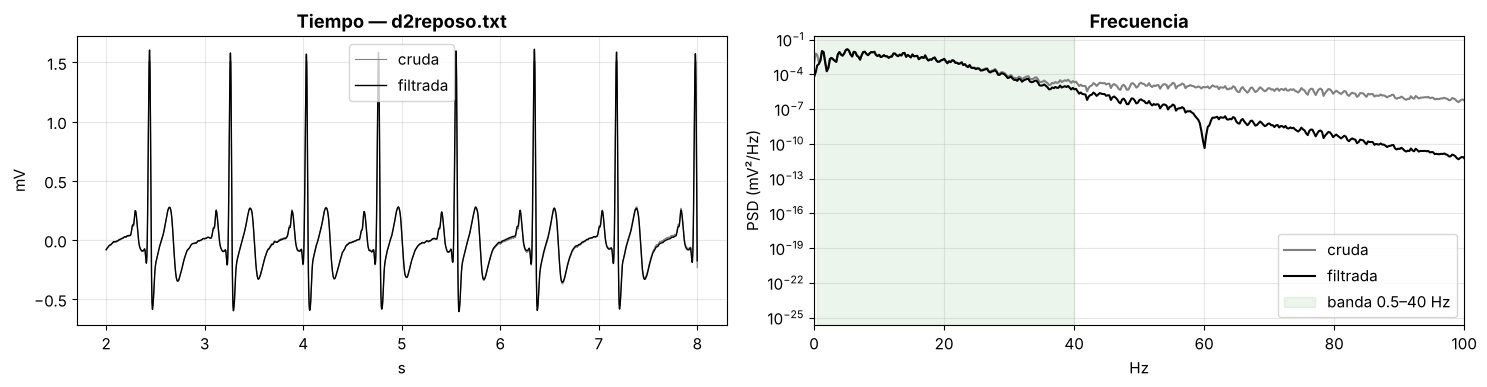

In [10]:
r = senales[REGISTROS[CLASES[0]][0]]
x_crudo = r["ecg_mV"] - np.mean(r["ecg_mV"])
signo = -1 if r["invertida"] else 1
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sl = (r["t"] >= 2) & (r["t"] < 8)
ax[0].plot(r["t"][sl], signo * x_crudo[sl], color="gray", lw=0.8, label="cruda")
ax[0].plot(r["t"][sl], r["ecg"][sl], color="black", lw=1, label="filtrada")
ax[0].set_title(f"Tiempo — {REGISTROS[CLASES[0]][0]}"); ax[0].set_xlabel("s"); ax[0].set_ylabel("mV"); ax[0].legend()
for s, nom, col in [(x_crudo, "cruda", "gray"), (r["ecg"], "filtrada", "black")]:
    f, P = signal.welch(s, fs=FS, nperseg=4096)
    ax[1].semilogy(f, P, color=col, label=nom)
ax[1].axvspan(0.5, 40, color="green", alpha=0.08, label="banda 0.5–40 Hz")
ax[1].set_xlim(0, 100); ax[1].set_xlabel("Hz"); ax[1].set_ylabel("PSD (mV²/Hz)"); ax[1].set_title("Frecuencia")
ax[1].legend(); plt.tight_layout(); plt.show()

### 🔎 Observa
- **En el tiempo:** la señal filtrada (negra) queda centrada en cero y sin "olas" lentas. La forma de P, QRS y T se conserva.
- **En la frecuencia:** por debajo de 0.5 Hz y por encima de 40 Hz la potencia cae fuertemente. Dentro de la banda, ambas curvas coinciden: **no se deformó la parte útil**.

<a id="B3"></a>
## B.3 Algoritmo de detección de picos R (Pan-Tompkins)

### 📖 Definición fácil
Para analizar latidos primero hay que **encontrarlos**. El punto más fácil de encontrar es el **pico R**: es el más alto y el más "rápido" del latido.

El algoritmo de **Pan y Tompkins (1985)** es el detector de QRS más conocido. Su idea es **resaltar lo que hace único al QRS** (cambios muy rápidos y grandes) y **apagar lo demás** (las ondas P y T, que son lentas):

| Paso | Operación | ¿Por qué? |
|---|---|---|
| 1 | **Pasa-banda 5–15 Hz** | La energía del QRS está en esa banda; P y T son más lentas |
| 2 | **Derivada** | El QRS tiene las pendientes más empinadas del latido |
| 3 | **Elevar al cuadrado** | Todo queda positivo y las pendientes grandes se agrandan aún más |
| 4 | **Integración en ventana móvil (150 ms)** | Convierte cada QRS en una sola "joroba" suave |
| 5 | **Umbral + periodo refractario (250 ms)** | Una joroba que supera el umbral es un latido; no puede haber dos latidos en menos de 250 ms (máx. 240 lpm) |
| 6 | **Ubicar el R** | Dentro de ±100 ms de cada joroba se busca el máximo del ECG filtrado |

> 💡 **Analogía:** es como buscar a la persona más alta de una foto grupal. Primero quitas el fondo (filtro), luego resaltas lo que destaca (derivada y cuadrado) y finalmente señalas a quien supera cierta altura (umbral).

La función `detectar_picos_R` que usamos en la Parte A implementa exactamente estos pasos. Ahora vemos qué hace cada uno.

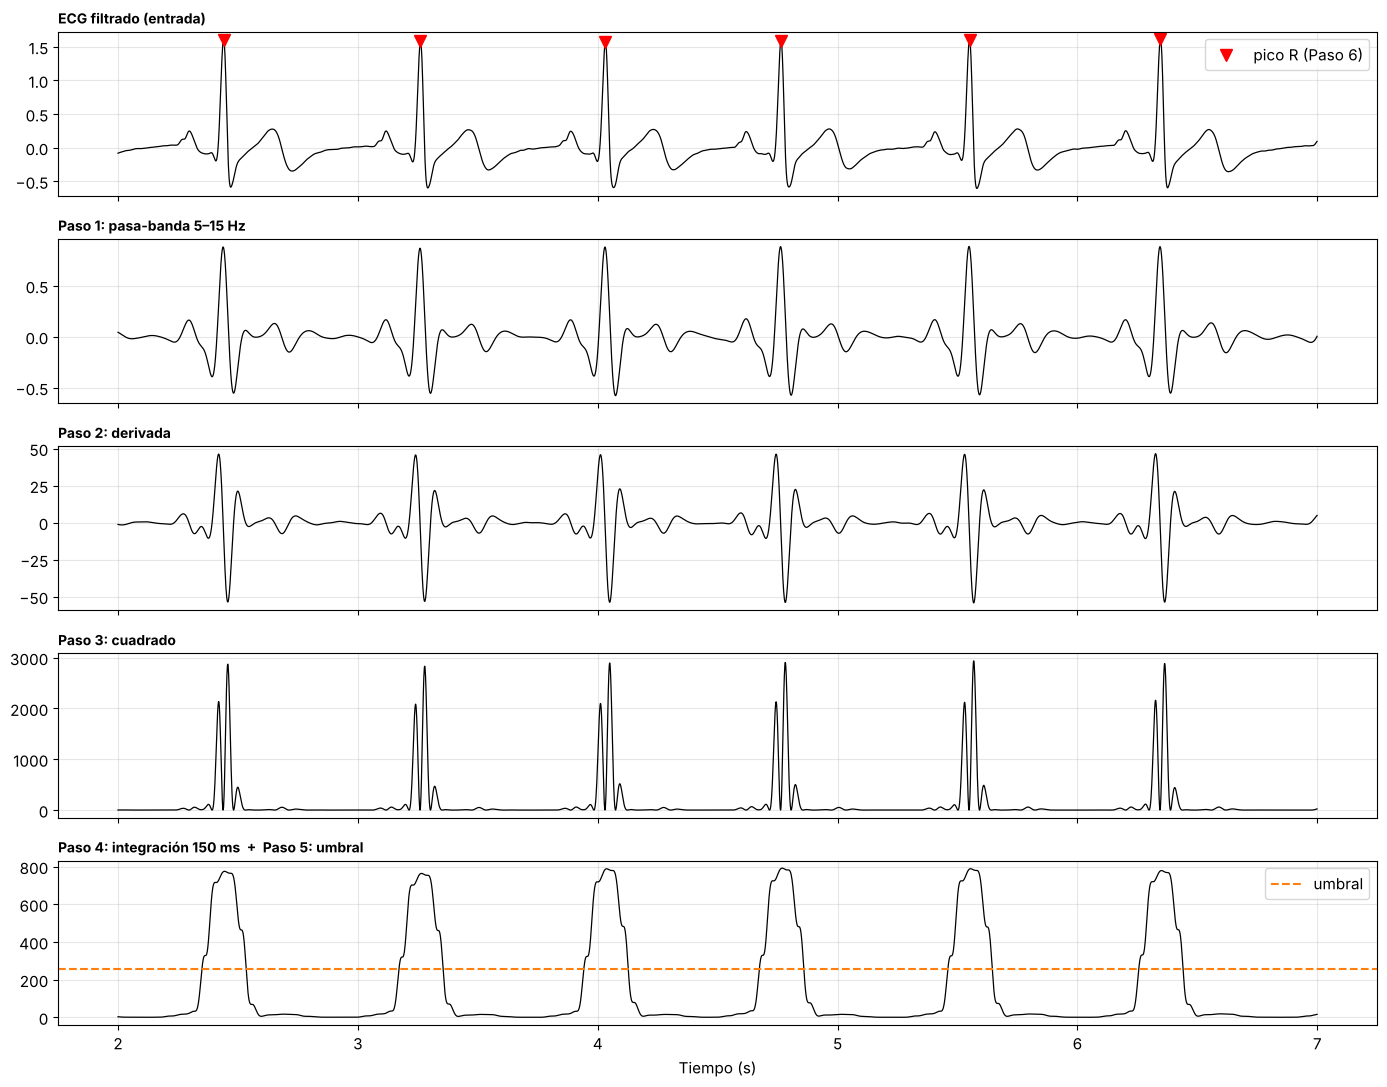

In [11]:
picos, pasos = detectar_picos_R(r["ecg"], mostrar=True)
sl = (r["t"] >= 2) & (r["t"] < 7)
titulos = ["ECG filtrado (entrada)", "Paso 1: pasa-banda 5–15 Hz", "Paso 2: derivada",
           "Paso 3: cuadrado", "Paso 4: integración 150 ms  +  Paso 5: umbral"]
fig, ax = plt.subplots(5, 1, figsize=(14, 11), sharex=True)
for a, s, tit in zip(ax, [r["ecg"], *pasos[:4]], titulos):
    a.plot(r["t"][sl], s[sl], color="black", lw=0.9); a.set_title(tit, loc="left", fontsize=10)
ax[4].axhline(pasos[4], color="tab:orange", ls="--", label="umbral"); ax[4].legend(loc="upper right")
p_vis = picos[(r["t"][picos] >= 2) & (r["t"][picos] < 7)]
ax[0].plot(r["t"][p_vis], r["ecg"][p_vis], "rv", ms=9, label="pico R (Paso 6)"); ax[0].legend(loc="upper right")
ax[-1].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

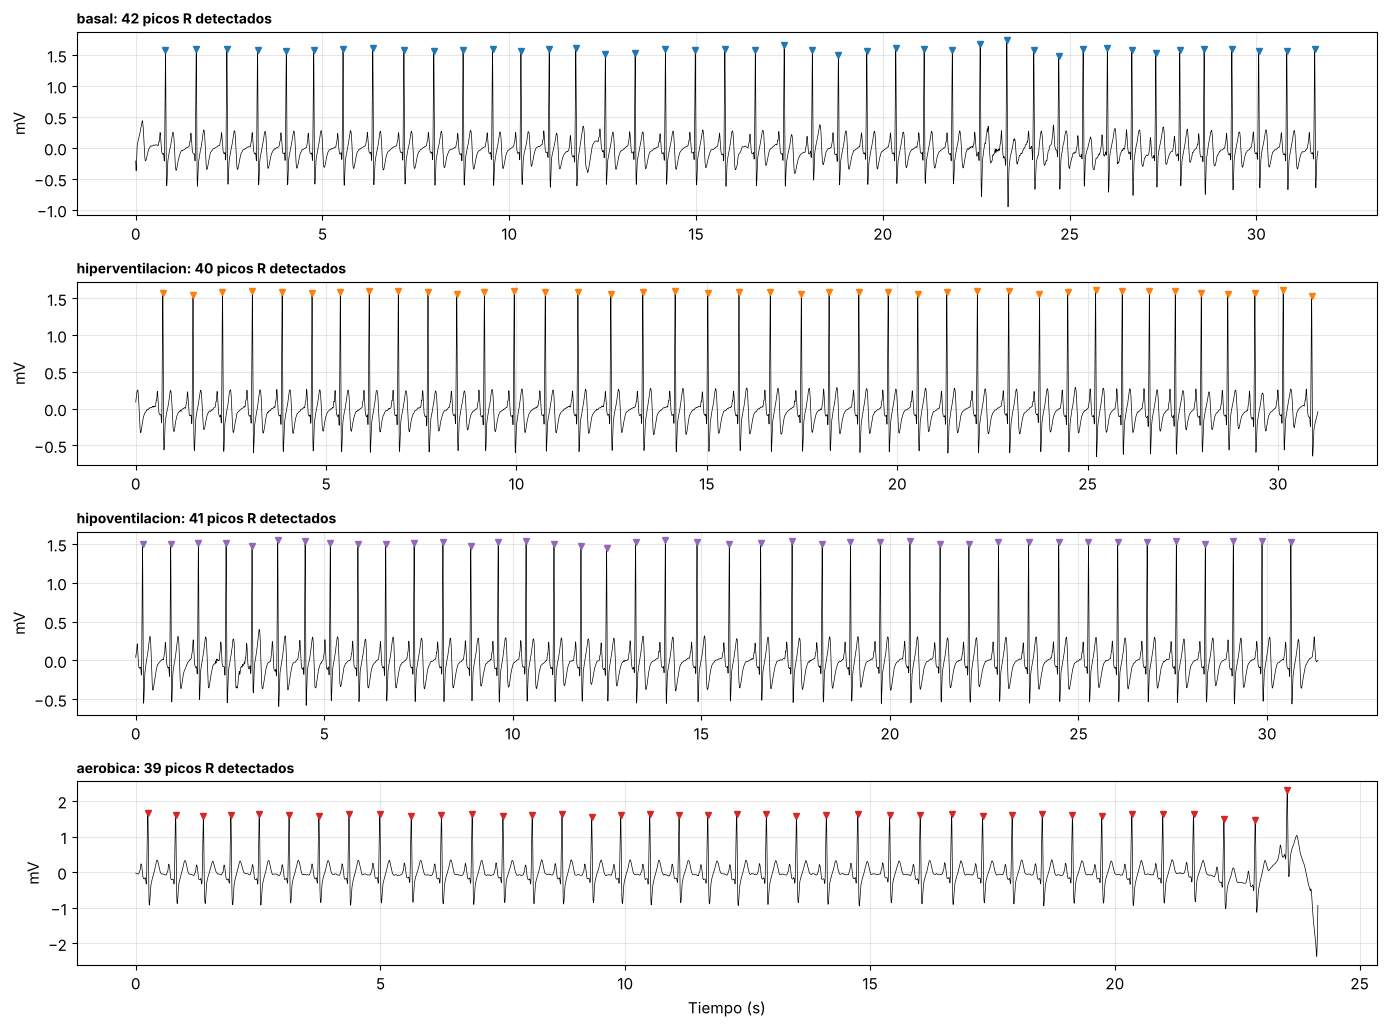

In [12]:
# Resultado del detector en los registros seleccionados
fig, ax = plt.subplots(len(CLASES), 1, figsize=(14, 2.6*len(CLASES)), squeeze=False)
for a, c in zip(ax[:, 0], CLASES):
    rr_ = senales[REGISTROS[c][0]]
    a.plot(rr_["t"], rr_["ecg"], color="black", lw=0.5)
    a.plot(rr_["t"][rr_["picos_R"]], rr_["ecg"][rr_["picos_R"]], "v", color=COLOR[c], ms=5)
    a.set_title(f"{c}: {len(rr_['picos_R'])} picos R detectados", loc="left", fontsize=10); a.set_ylabel("mV")
ax[-1, 0].set_xlabel("Tiempo (s)"); plt.tight_layout(); plt.show()

### 🔎 Observa la transformación
- En el **Paso 1** las ondas P y T casi desaparecen; el QRS queda como una oscilación rápida.
- En el **Paso 3** solo sobreviven picos positivos, y los del QRS son mucho mayores que el resto.
- En el **Paso 4** cada latido es **una sola joroba**: basta un umbral para contarlas.

### ✍️ Pregunta B.1
1. ¿Cada triángulo cae sobre un pico R? ¿Ves latidos sin marcar (**falsos negativos**) o marcas sobre ruido (**falsos positivos**)?
2. ¿Por qué el Paso 2 (derivada) ayuda a distinguir el QRS de la onda T, aunque la onda T también sea grande?

✍️ **Respuesta:**

1. Sí, cada triángulo cae sobre un pico R. No vemos latidos sin marcar ni marcas sobre ruido. Además, el porcentaje de RR anómalos fue 0 % en las cuatro condiciones y los RR están entre 0.56 s y 0.87 s, que son valores fisiológicos.
2. La derivada mide la pendiente, no la altura. La onda T puede ser grande, pero sube y baja lento (dura ~150–200 ms), así que su derivada es pequeña. El QRS cambia de valor en pocos milisegundos, por eso su derivada es mucho mayor. Al elevar al cuadrado, esa diferencia se agranda todavía más y la T casi desaparece en el paso 4.

<a id="B4"></a>
## B.4 Segmentación en latidos

### 📖 Definición fácil
Ya sabemos **dónde** está cada R. Ahora "recortamos" una ventana alrededor de él: **200 ms antes y 400 ms después**, como en el material de clase. Cada recorte es **un latido** y será **una fila** de nuestra tabla de datos.

```
          200 ms        400 ms
       |←-------→R←------------------→|
          P   Q  R  S        T
```

**Control de calidad** (el mismo de la Parte A):
- Se descartan el **primer y el último** latido, porque no tienen RR a ambos lados.
- Se descartan los latidos con **RR anómalo** (más de 35 % distinto de la mediana local).

Matriz de latidos: (154, 600) → (n.º de latidos, muestras por latido)


,latidos válidos
clase,
basal,40
hiperventilacion,38
hipoventilacion,39
aerobica,37


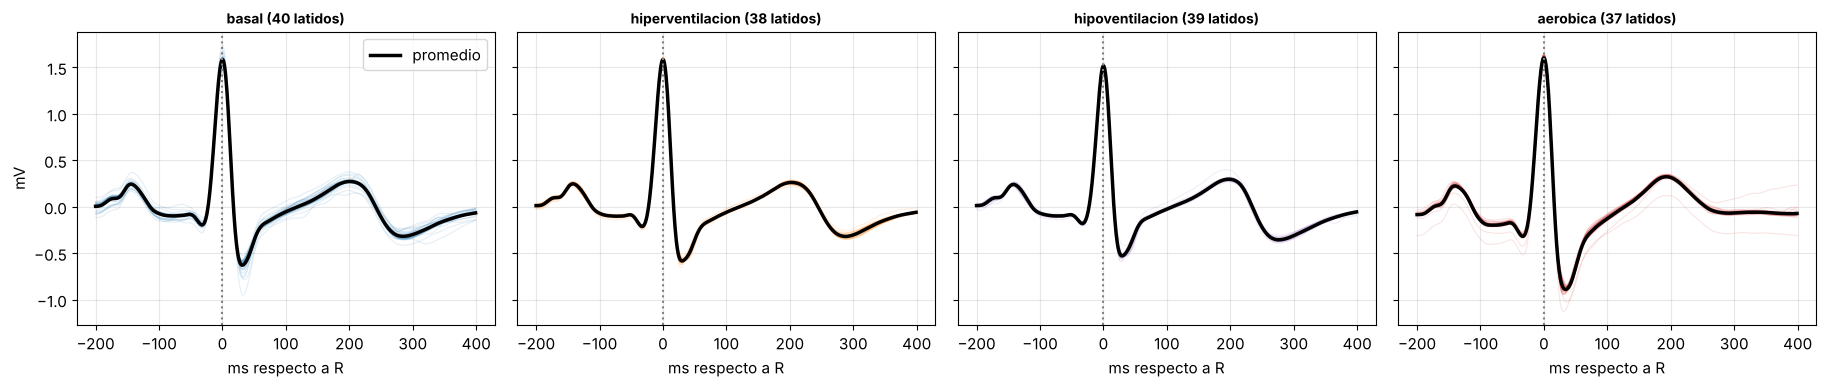

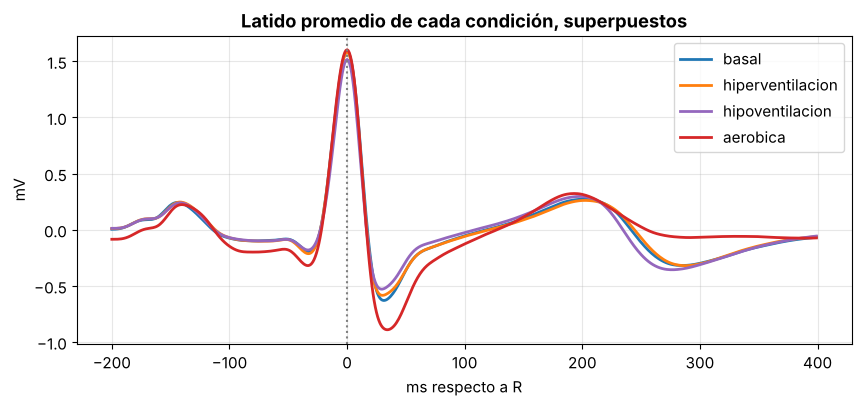

In [13]:
ANTES, DESPUES = int(0.200 * FS), int(0.400 * FS)
i0 = ANTES                                      # posición del pico R dentro de cada latido
t_lat = (np.arange(ANTES + DESPUES) - ANTES) / FS * 1000   # eje en ms (R en 0)

def segmentar(registros_dict):
    latidos, info = [], []
    for c, archivos in registros_dict.items():
        for a in archivos:
            rr_ = senales[a]
            for k in rr_["validos"]:
                p = rr_["picos_R"][k]
                latidos.append(rr_["ecg"][p - ANTES: p + DESPUES])
                info.append({"clase": c, "archivo": a, "t_R": p / FS,
                             "RR_prev": rr_["rr"][k - 1], "RR_next": rr_["rr"][k]})
    return np.array(latidos), pd.DataFrame(info)

latidos, info = segmentar(REGISTROS)
print("Matriz de latidos:", latidos.shape, "→ (n.º de latidos, muestras por latido)")
display(info.groupby("clase").size().reindex(CLASES).rename("latidos válidos").to_frame())

fig, ax = plt.subplots(1, len(CLASES), figsize=(4.6*len(CLASES), 4), sharey=True, squeeze=False)
for a, c in zip(ax[0], CLASES):
    L = latidos[info["clase"] == c]
    a.plot(t_lat, L.T, color=COLOR[c], alpha=0.12, lw=0.8)
    a.plot(t_lat, L.mean(axis=0), color="black", lw=2.5, label="promedio")
    a.axvline(0, color="gray", ls=":"); a.set_title(f"{c} ({len(L)} latidos)", fontsize=10)
    a.set_xlabel("ms respecto a R")
ax[0, 0].set_ylabel("mV"); ax[0, 0].legend(loc="upper right"); plt.tight_layout(); plt.show()

plt.figure(figsize=(10, 4))
for c in CLASES:
    plt.plot(t_lat, latidos[info["clase"] == c].mean(axis=0), color=COLOR[c], lw=2, label=c)
plt.axvline(0, color="gray", ls=":"); plt.xlabel("ms respecto a R"); plt.ylabel("mV")
plt.title("Latido promedio de cada condición, superpuestos"); plt.legend(); plt.show()

### ✍️ Pregunta B.2
Compara los **latidos promedio** de las condiciones:
1. ¿Cambia la **altura del pico R**?
2. ¿La **onda T** está a la misma distancia del R y tiene la misma altura en todas las condiciones?

✍️ **Respuesta:**

1. La altura del R casi no cambia: los promedios medidos están entre 1.61 y 1.79 mV (hipoventilación la menor y aeróbica la mayor). Hay que tomar esto con cuidado porque las puntas del R están saturadas, entonces las diferencias reales de amplitud R pueden estar escondidas. Lo que sí cambia claramente es la onda S, que en la aeróbica es más profunda (−0.71 mV, frente a −0.44 a −0.54 mV en las otras).
2. No es igual. En la aeróbica el máximo de la T está algo más cerca del R (tiempo R→T ≈ 193 ms frente a 197–202 ms en las demás) y es más alto (0.51 mV frente a ~0.36–0.39 mV). Además, después de la T la señal no baja como en las otras condiciones. El acortamiento R→T con FC alta es lo esperado, porque la repolarización (QT) se acorta cuando el corazón late más rápido. Basal, hiper e hipoventilación tienen latidos promedio casi superpuestos.

<a id="B5"></a>
## B.5 Extracción de características (5 familias)

Siguiendo el artículo base, describimos cada latido con **cinco familias** de características, **24 en total**:

| Familia | Pregunta que responde | Características |
|---|---|---|
| **1. Ritmo** | ¿Cuándo llegó el latido? | RR previo, RR siguiente, FC instantánea |
| **2. Morfológicas** | ¿Qué forma tiene? | Amplitudes de P, Q, R, S y T; duración Q–S; tiempo R→T |
| **3. Estadísticas básicas** | ¿Cómo se reparten sus valores? | Media, mediana, desviación estándar, percentiles 25 y 75 |
| **4. Orden superior (HOS)** | ¿Es simétrico? ¿Es puntiagudo? | Asimetría (*skewness*) y curtosis |
| **5. Frecuencia** | ¿De qué "notas" está hecho? | FFT: frecuencia dominante, potencia 0.5–40 Hz, fracción 5–15 Hz · Wavelet: energía de 4 niveles |

### B.5.1 Ritmo y morfología

📖 **Ritmo:** el **RR previo** es el tiempo desde el latido anterior y el **RR siguiente**, hasta el próximo. La **FC instantánea** es $60 / RR_{previo}$.

📖 **Morfología:** son medidas directas sobre la forma del latido, como si usaras una regla sobre el papel del electrocardiógrafo. Todas las amplitudes se miden respecto a la **línea isoeléctrica** (el "cero" del corazón, estimado en el segmento PR):

| Medida | Ventana de búsqueda (respecto a R) |
|---|---|
| Línea isoeléctrica | Promedio entre −100 y −60 ms |
| **Amplitud P** | Máximo entre −200 y −80 ms |
| **Amplitud Q** | Mínimo entre −60 y 0 ms |
| **Amplitud R** | Valor en el pico R |
| **Amplitud S** | Mínimo entre 0 y +80 ms |
| **Duración Q–S** | Tiempo entre Q y S (aproxima la duración del QRS) |
| **Amplitud T** y **tiempo R→T** | Máximo entre +150 y +400 ms, y cuánto tarda en llegar desde R |

> ⚠️ Son **aproximaciones didácticas** con ventanas fijas. Los programas clínicos usan algoritmos de delineación más elaborados.

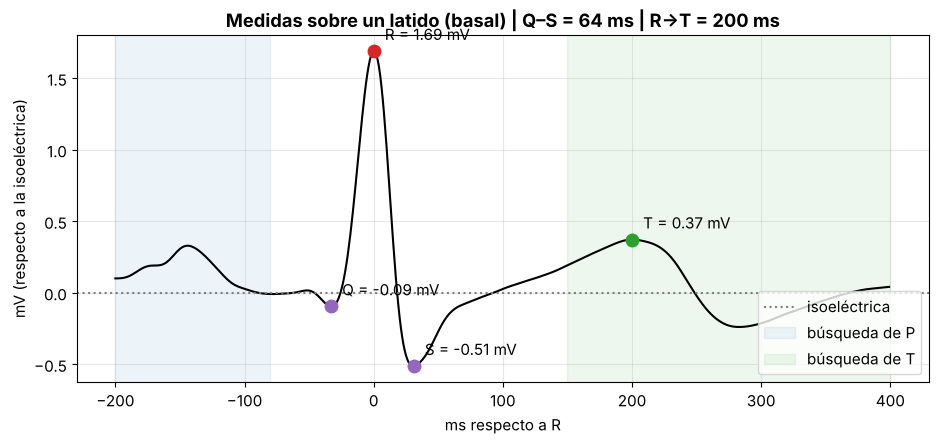

RR_prev_ms    786.000
RR_next_ms    796.000
FC_lpm         76.336
amp_P           0.329
amp_Q          -0.095
amp_R           1.691
amp_S          -0.512
amp_T           0.372
dur_QS_ms      64.000
t_RT_ms       200.000
dtype: float64

In [14]:
ms = lambda v: int(round(v * FS / 1000))   # milisegundos → número de muestras

def puntos_clave(lat):
    iso = np.mean(lat[i0 - ms(100): i0 - ms(60)])
    x = lat - iso
    iQ = i0 - ms(60) + np.argmin(x[i0 - ms(60): i0])
    iS = i0 + np.argmin(x[i0: i0 + ms(80)])
    iT = i0 + ms(150) + np.argmax(x[i0 + ms(150): i0 + ms(400)])
    return iso, iQ, iS, iT

def caracteristicas_ritmo_morfologia(lat, rr_prev, rr_next):
    iso, iQ, iS, iT = puntos_clave(lat)
    x = lat - iso
    return {"RR_prev_ms": rr_prev * 1000, "RR_next_ms": rr_next * 1000, "FC_lpm": 60 / rr_prev,
            "amp_P": np.max(x[i0 - ms(200): i0 - ms(80)]), "amp_Q": x[iQ], "amp_R": x[i0],
            "amp_S": x[iS], "amp_T": x[iT],
            "dur_QS_ms": (iS - iQ) / FS * 1000, "t_RT_ms": (iT - i0) / FS * 1000}

# Ejemplo sobre un latido basal
k = int(np.flatnonzero(info["clase"] == CLASES[0])[5])
lat_ej = latidos[k]
c_ej = caracteristicas_ritmo_morfologia(lat_ej, info.RR_prev[k], info.RR_next[k])
iso, iQ, iS, iT = puntos_clave(lat_ej)
plt.figure(figsize=(11, 4.5))
plt.plot(t_lat, lat_ej - iso, color="black", lw=1.5); plt.axhline(0, color="gray", ls=":", label="isoeléctrica")
for nom, idx, col in [("Q", iQ, "tab:purple"), ("R", i0, "tab:red"), ("S", iS, "tab:purple"), ("T", iT, "tab:green")]:
    plt.plot(t_lat[idx], lat_ej[idx] - iso, "o", color=col, ms=9)
    plt.annotate(f"{nom} = {c_ej['amp_' + nom]:.2f} mV", (t_lat[idx], lat_ej[idx] - iso),
                 textcoords="offset points", xytext=(8, 8))
plt.axvspan(-200, -80, color="tab:blue", alpha=0.08, label="búsqueda de P")
plt.axvspan(150, 400, color="tab:green", alpha=0.08, label="búsqueda de T")
plt.title(f"Medidas sobre un latido ({CLASES[0]}) | Q–S = {c_ej['dur_QS_ms']:.0f} ms | R→T = {c_ej['t_RT_ms']:.0f} ms")
plt.xlabel("ms respecto a R"); plt.ylabel("mV (respecto a la isoeléctrica)"); plt.legend(loc="lower right"); plt.show()
pd.Series(c_ej).round(3)

### B.5.2 Estadísticas básicas y de orden superior (HOS)

📖 Tomamos los 600 valores del latido como si fueran **notas de un examen** y calculamos:

| Característica | Definición fácil |
|---|---|
| **Media / mediana** | Valor "típico" del latido |
| **Desviación estándar** | Cuánto se alejan los valores de la media; relacionada con la energía del latido |
| **Percentiles 25 y 75** | Valores por debajo de los cuales está el 25 % y el 75 % de las muestras |
| **Asimetría (skewness)** | ¿La distribución se carga hacia un lado? Un R alto y estrecho da asimetría **positiva** |
| **Curtosis** | ¿Hay valores extremos aislados? Un R muy agudo con el resto plano da curtosis **alta** |

Asimetría y curtosis son estadísticas de **3.er y 4.º orden** (HOS). Capturan información **no lineal** de la forma.

### B.5.3 Espectrales (FFT del latido)

📖 La **FFT** descompone el latido en "notas musicales" (frecuencias). Medimos:
- **Frecuencia dominante:** la frecuencia con más potencia.
- **Potencia total en 0.5–40 Hz:** la energía del latido en la banda útil.
- **Fracción en 5–15 Hz:** qué parte de la energía pertenece a la banda del QRS, la misma del Paso 1 de Pan-Tompkins.

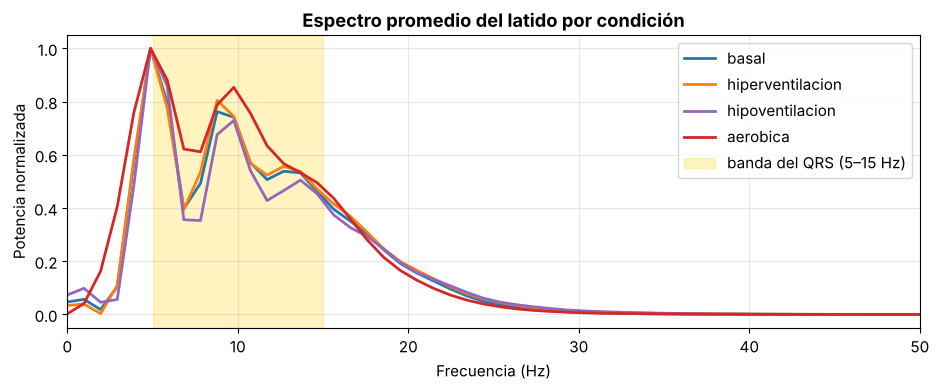

In [15]:
def caracteristicas_estadisticas(lat):
    return {"media": np.mean(lat), "mediana": np.median(lat), "desv_est": np.std(lat),
            "p25": np.percentile(lat, 25), "p75": np.percentile(lat, 75),
            "asimetria": skew(lat), "curtosis": kurtosis(lat)}

def caracteristicas_espectrales(lat, fs=FS, nfft=1024):
    x = (lat - np.mean(lat)) * np.hanning(len(lat))
    f = np.fft.rfftfreq(nfft, 1/fs)
    P = np.abs(np.fft.rfft(x, nfft))**2
    banda = (f >= 0.5) & (f <= 40)
    return {"f_dominante_Hz": f[banda][np.argmax(P[banda])],
            "potencia_0.5_40": P[banda].sum() / fs,
            "frac_5_15Hz": P[(f >= 5) & (f <= 15)].sum() / P[banda].sum()}

f = np.fft.rfftfreq(1024, 1/FS)
plt.figure(figsize=(11, 3.8))
for c in CLASES:
    L = latidos[info["clase"] == c]
    P = np.mean([np.abs(np.fft.rfft((l - l.mean()) * np.hanning(len(l)), 1024))**2 for l in L], axis=0)
    plt.plot(f, P / P.max(), color=COLOR[c], lw=2, label=c)
plt.axvspan(5, 15, color="gold", alpha=0.25, label="banda del QRS (5–15 Hz)")
plt.xlim(0, 50); plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Potencia normalizada")
plt.title("Espectro promedio del latido por condición"); plt.legend(); plt.show()

### B.5.4 Wavelet (DWT)

📖 **Definición fácil:** la FFT dice *qué* frecuencias hay, pero no *dónde* están dentro del latido. La **transformada wavelet discreta (DWT)** separa el latido en **capas**, como un ecualizador de música. Cada capa (nivel) contiene un rango de frecuencias y **conserva la ubicación en el tiempo**.

Usamos la wavelet **Daubechies 4 (db4)**, cuya forma se parece a un QRS; el material de clase menciona db4 y bior4.4. Con 6 niveles a 1000 Hz:

| Nivel | Banda aproximada | Qué contiene |
|---|---|---|
| **cA6** (aproximación) | 0 – 7.8 Hz | Ondas lentas: **P y T** |
| **cD6** | 7.8 – 15.6 Hz | Parte principal del **QRS** |
| **cD5** | 15.6 – 31 Hz | Bordes rápidos del **QRS** |
| **cD4** | 31 – 62.5 Hz | Muy poca energía (el filtro cortó en 40 Hz) |
| cD3–cD1 | > 62.5 Hz | Prácticamente vacíos → no se usan |

Como característica usamos la **energía relativa** de cada nivel: qué porcentaje de la energía total del latido está en esa capa.

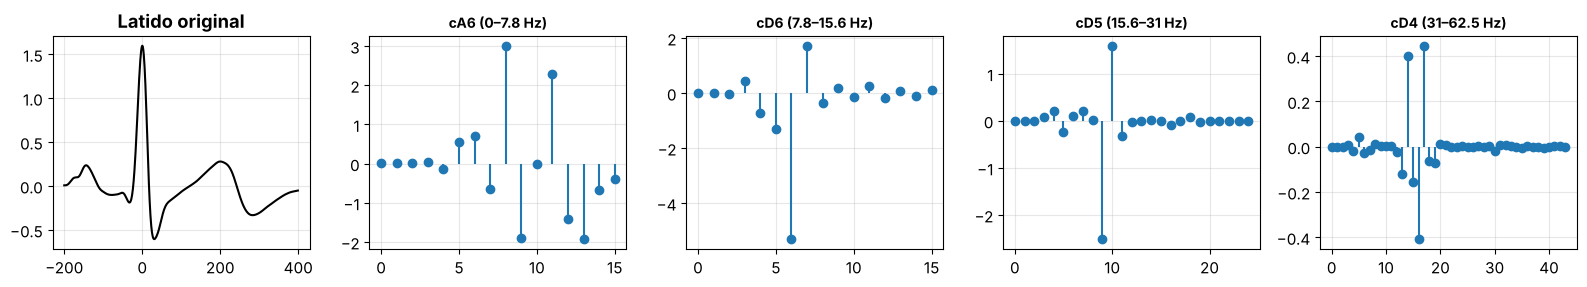

wav_E_cA6    0.368
wav_E_cD6    0.491
wav_E_cD5    0.132
wav_E_cD4    0.008
dtype: float64

In [16]:
def caracteristicas_wavelet(lat, wavelet="db4", nivel=6):
    coef = pywt.wavedec(lat - np.mean(lat), wavelet, level=nivel)   # [cA6, cD6, cD5, cD4, cD3, cD2, cD1]
    E = np.array([np.sum(c**2) for c in coef]); E = E / E.sum()
    return {"wav_E_cA6": E[0], "wav_E_cD6": E[1], "wav_E_cD5": E[2], "wav_E_cD4": E[3]}

coef = pywt.wavedec(lat_ej - np.mean(lat_ej), "db4", level=6)
fig, ax = plt.subplots(1, 5, figsize=(16, 3))
ax[0].plot(t_lat, lat_ej, color="black"); ax[0].set_title("Latido original")
for a, cf, nom in zip(ax[1:], coef[:4], ["cA6 (0–7.8 Hz)", "cD6 (7.8–15.6 Hz)", "cD5 (15.6–31 Hz)", "cD4 (31–62.5 Hz)"]):
    a.stem(cf, basefmt=" "); a.set_title(nom, fontsize=10)
plt.tight_layout(); plt.show()
pd.Series(caracteristicas_wavelet(lat_ej)).round(3)

<a id="B6"></a>
## B.6 La tabla de características: de señal a datos tabulares

Juntamos las cinco familias para **todos** los latidos. El resultado es una **tabla**:
- cada **fila** es un latido;
- cada **columna** es una característica;
- la columna `clase` es la condición, es decir, la **respuesta** que el clasificador debe aprender.

Es exactamente el tipo de datos tabulares que necesita un algoritmo de *machine learning*.

In [17]:
def construir_tabla(latidos, info):
    filas = []
    for k, lat in enumerate(latidos):
        fila = {}
        fila.update(caracteristicas_ritmo_morfologia(lat, info.RR_prev[k], info.RR_next[k]))
        fila.update(caracteristicas_estadisticas(lat))
        fila.update(caracteristicas_espectrales(lat))
        fila.update(caracteristicas_wavelet(lat))
        filas.append(fila)
    return pd.concat([pd.DataFrame(filas), info[["clase", "archivo", "t_R"]]], axis=1)

tabla = construir_tabla(latidos, info)
CARACTERISTICAS = [c for c in tabla.columns if c not in ("clase", "archivo", "t_R")]
print(f"Tabla de características: {len(tabla)} latidos × {len(CARACTERISTICAS)} características")
display(tabla.head())
print("Promedio de cada característica por condición:")
display(tabla.groupby("clase")[CARACTERISTICAS].mean().T.reindex(columns=CLASES).round(3))

Tabla de características: 154 latidos × 24 características


,RR_prev_ms,RR_next_ms,FC_lpm,amp_P,amp_Q,amp_R,amp_S,amp_T,dur_QS_ms,t_RT_ms,...,f_dominante_Hz,potencia_0.5_40,frac_5_15Hz,wav_E_cA6,wav_E_cD6,wav_E_cD5,wav_E_cD4,clase,archivo,t_R
0,824.0,819.0,72.815534,0.327681,-0.120859,1.683567,-0.531742,0.379202,63.0,202.0,...,4.882812,18.848574,0.589065,0.373625,0.469543,0.148362,0.008296,basal,d2reposo.txt,1.621
1,819.0,821.0,73.260073,0.331660,-0.111973,1.688997,-0.502715,0.360794,62.0,203.0,...,4.882812,18.363772,0.587786,0.390857,0.464481,0.135398,0.009088,basal,d2reposo.txt,2.440
2,821.0,771.0,73.081608,0.336095,-0.122885,1.668207,-0.509910,0.354792,63.0,200.0,...,4.882812,17.838118,0.593380,0.365456,0.486164,0.140081,0.008110,basal,d2reposo.txt,3.261
3,771.0,732.0,77.821012,0.332652,-0.115846,1.658356,-0.505353,0.359513,68.0,200.0,...,4.882812,18.002831,0.618452,0.370090,0.501935,0.121457,0.006345,basal,d2reposo.txt,4.032
4,732.0,786.0,81.967213,0.330667,-0.111874,1.675365,-0.492902,0.370603,66.0,201.0,...,4.882812,18.231800,0.613927,0.364985,0.504454,0.123195,0.007188,basal,d2reposo.txt,4.764


Promedio de cada característica por condición:


clase,basal,hiperventilacion,hipoventilacion,aerobica
RR_prev_ms,750.450,774.368,761.205,611.405
RR_next_ms,748.525,773.105,761.667,613.730
FC_lpm,80.425,77.797,79.078,98.258
amp_P,0.338,0.344,0.334,0.414
amp_Q,-0.102,-0.118,-0.088,-0.130
amp_R,1.679,1.680,1.609,1.792
amp_S,-0.538,-0.493,-0.441,-0.708
amp_T,0.368,0.357,0.390,0.513
dur_QS_ms,63.575,63.500,63.026,67.811
t_RT_ms,200.775,202.395,197.513,192.919


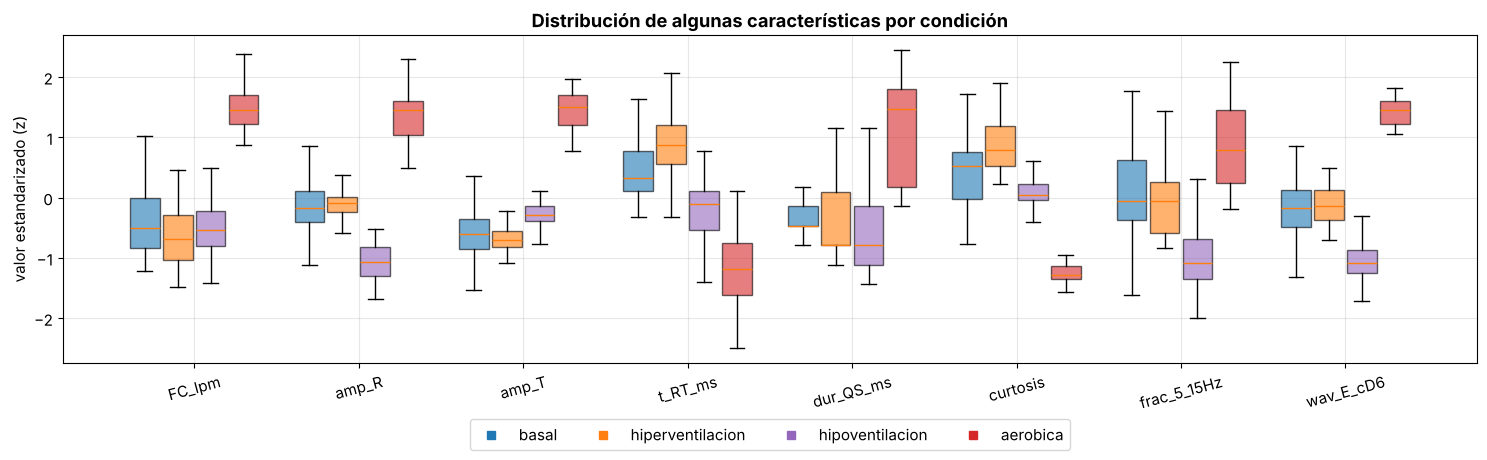

In [18]:
# ¿Qué características separan mejor las condiciones? Boxplots estandarizados (z-score)
sel = ["FC_lpm", "amp_R", "amp_T", "t_RT_ms", "dur_QS_ms", "curtosis", "frac_5_15Hz", "wav_E_cD6"]
z = (tabla[sel] - tabla[sel].mean()) / tabla[sel].std()
fig, ax = plt.subplots(figsize=(15, 4.8))
ancho = 0.8 / len(CLASES)
for j, c in enumerate(CLASES):
    pos = np.arange(len(sel)) + (j - (len(CLASES) - 1) / 2) * ancho
    bp = ax.boxplot([z[tabla.clase == c][s] for s in sel], positions=pos, widths=ancho*0.9,
                    patch_artist=True, showfliers=False)
    for caja in bp["boxes"]:
        caja.set_facecolor(COLOR[c]); caja.set_alpha(0.6)
    ax.plot([], [], "s", color=COLOR[c], label=c)
ax.set_xticks(np.arange(len(sel))); ax.set_xticklabels(sel, rotation=15)
ax.set_ylabel("valor estandarizado (z)"); ax.set_title("Distribución de algunas características por condición")
ax.legend(ncol=len(CLASES), loc="upper center", bbox_to_anchor=(0.5, -0.15)); plt.tight_layout(); plt.show()

### ✍️ Pregunta B.3
1. Mirando los boxplots, ¿qué **dos características** separan mejor tus condiciones? ¿Tiene sentido fisiológico?
2. ¿Qué dos condiciones se **parecen más** entre sí en casi todas las características?

✍️ **Respuesta:**

1. Las que mejor separan son **amp_T** y **wav_E_cD6** (también FC_lpm y curtosis). Las cuatro separan sobre todo la condición aeróbica del resto, y en wav_E_cD6 y amp_R la hipoventilación también queda por debajo de las demás. Tiene sentido fisiológico porque después del ejercicio cambia la FC y también la repolarización (T más alta y más cercana al R) y la forma del QRS (S más profunda, más energía en la banda de 7.8–15.6 Hz). En la hipoventilación, el menor R podría deberse a que con los pulmones llenos cambia la posición del corazón y la impedancia del tórax, aunque también podría influir el contacto de los electrodos entre registros.
2. **Basal e hiperventilación** son las que más se parecen: sus cajas se superponen en casi todas las características y sus latidos promedio están prácticamente encima uno del otro.

<a id="B7"></a>
## B.7 Clasificación: comparación de 5 algoritmos

### 📖 Definición fácil de cada clasificador (los mismos del artículo base)

| Algoritmo | Idea en una frase | Analogía |
|---|---|---|
| **Árbol de Decisión (DT)** | Hace preguntas de sí/no ("¿FC > 90?") hasta decidir | Un diagrama de flujo |
| **Regresión Logística (LR)** | Suma las características con pesos y calcula la probabilidad de cada clase | Una balanza que suma evidencias |
| **Random Forest (RF)** | Entrena muchos árboles distintos y decide por votación | Un comité de expertos |
| **KNN** | Mira los *k* latidos más parecidos ya conocidos y copia su clase | "Dime con quién andas..." |
| **SVM** | Busca la frontera que deja el mayor margen entre las clases | Trazar la "calle" más ancha entre grupos |

En el artículo base, **Random Forest** obtuvo la mayor exactitud (~98 %).

### 📖 ¿Cómo evaluamos sin hacer "trampa"?
Un modelo se evalúa con datos que **no vio** al entrenar. Pero **latidos consecutivos son casi idénticos**: si mezclamos al azar, el modelo se entrena con el latido 10 y se evalúa con el 11, ¡que es casi una copia! El resultado sería **demasiado optimista**. Esto se llama **fuga de datos**.

**Solución:** agrupamos los latidos en **bloques de 10 segundos**. Cada bloque va **entero** a entrenamiento o a prueba, nunca a ambos. Usamos `StratifiedGroupKFold`: respeta los bloques y procura que cada pliegue tenga todas las condiciones.

### 📖 Métricas
- **Exactitud (accuracy):** % de latidos bien clasificados.
- **F1 macro:** promedio del F1 de cada clase. Es más justo cuando una clase tiene más latidos que otra.
- La línea punteada **"azar"** marca el rendimiento de adivinar ($1/\text{n.º de clases}$).

154 latidos | 14 bloques de 10 s | 3 pliegues | 4 clases → azar = 0.25


,Exactitud,± exac.,F1 macro,± F1
Modelo,,,,
Árbol de Decisión,0.748,0.058,0.738,0.051
Regresión Logística,0.906,0.041,0.904,0.040
Random Forest,0.852,0.070,0.850,0.066
KNN (k=5),0.856,0.011,0.842,0.014
SVM (RBF),0.882,0.033,0.868,0.038


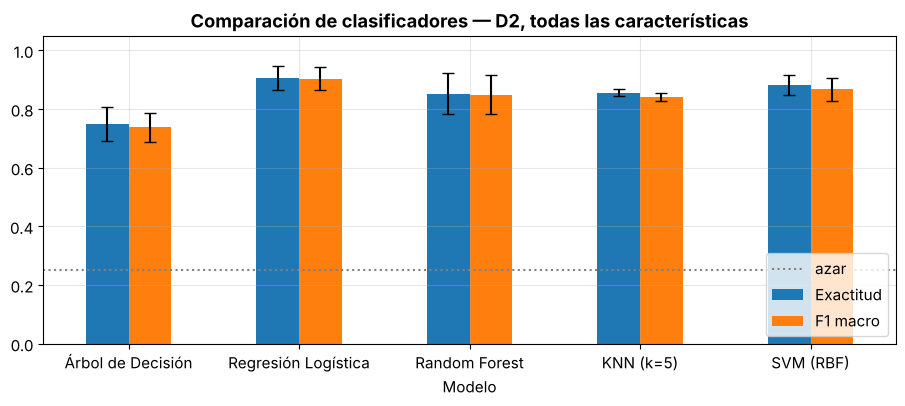

In [19]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay

MODELOS = {
    "Árbol de Decisión":   lambda: DecisionTreeClassifier(max_depth=5, random_state=0),
    "Regresión Logística": lambda: LogisticRegression(max_iter=3000),
    "Random Forest":       lambda: RandomForestClassifier(n_estimators=200, random_state=0),
    "KNN (k=5)":           lambda: KNeighborsClassifier(n_neighbors=5),
    "SVM (RBF)":           lambda: SVC(kernel="rbf"),
}
nuevo_modelo = lambda nombre: make_pipeline(StandardScaler(), MODELOS[nombre]())

def esquema_validacion(tabla):
    grupos = (tabla["archivo"] + "_b" + (tabla["t_R"] // 10).astype(int).astype(str)).to_numpy()
    n = int(min(5, tabla.assign(g=grupos).groupby("clase")["g"].nunique().min()))
    assert n >= 2, "Se necesitan al menos 2 bloques de 10 s por condición."
    return StratifiedGroupKFold(n_splits=n, shuffle=True, random_state=0), grupos, n

def comparar_modelos(tabla, columnas):
    cv, grupos, _ = esquema_validacion(tabla)
    filas = []
    for nombre in MODELOS:
        s = cross_validate(nuevo_modelo(nombre), tabla[columnas].to_numpy(), tabla["clase"].to_numpy(),
                           cv=cv, groups=grupos, scoring=["accuracy", "f1_macro"])
        filas.append({"Modelo": nombre, "Exactitud": s["test_accuracy"].mean(), "± exac.": s["test_accuracy"].std(),
                      "F1 macro": s["test_f1_macro"].mean(), "± F1": s["test_f1_macro"].std()})
    return pd.DataFrame(filas).set_index("Modelo")

_, grupos, n_pliegues = esquema_validacion(tabla)
print(f"{len(tabla)} latidos | {len(np.unique(grupos))} bloques de 10 s | {n_pliegues} pliegues | "
      f"{len(CLASES)} clases → azar = {1/len(CLASES):.2f}")
resultados = comparar_modelos(tabla, CARACTERISTICAS)
display(resultados.round(3))

ax = resultados[["Exactitud", "F1 macro"]].plot.bar(figsize=(11, 4), rot=0,
                                                    yerr=resultados[["± exac.", "± F1"]].values.T, capsize=4)
ax.axhline(1/len(CLASES), color="gray", ls=":", label="azar"); ax.set_ylim(0, 1.05)
ax.set_title(f"Comparación de clasificadores — {DERIVACION}, todas las características"); ax.legend(loc="lower right")
plt.show()

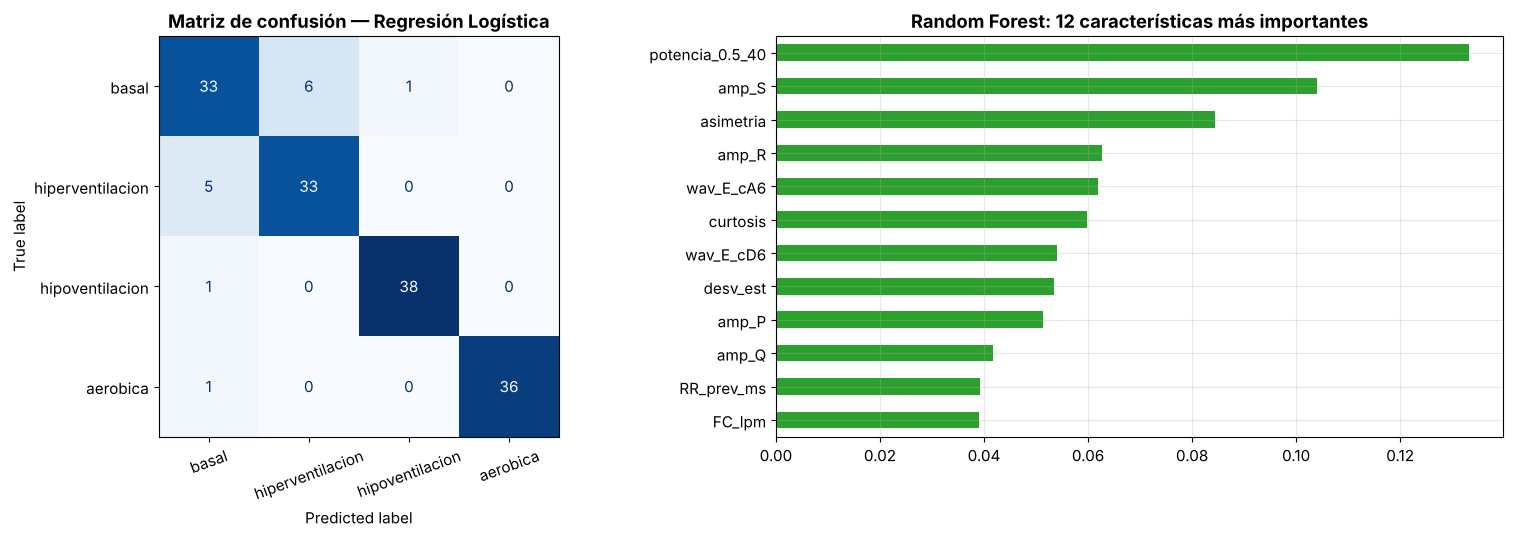

In [20]:
# Matriz de confusión del mejor modelo e importancia de características (Random Forest)
mejor = resultados["F1 macro"].idxmax()
cv, grupos, _ = esquema_validacion(tabla)
y = tabla["clase"].to_numpy()
y_pred = cross_val_predict(nuevo_modelo(mejor), tabla[CARACTERISTICAS].to_numpy(), y, cv=cv, groups=grupos)
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1, 1.1]})
ConfusionMatrixDisplay.from_predictions(y, y_pred, labels=CLASES, cmap="Blues", ax=ax[0], colorbar=False,
                                        xticks_rotation=20)
ax[0].set_title(f"Matriz de confusión — {mejor}"); ax[0].grid(False)
rf = nuevo_modelo("Random Forest").fit(tabla[CARACTERISTICAS].to_numpy(), y)
imp = pd.Series(rf[-1].feature_importances_, index=CARACTERISTICAS).sort_values()
imp.tail(12).plot.barh(ax=ax[1], color="tab:green"); ax[1].set_title("Random Forest: 12 características más importantes")
plt.tight_layout(); plt.show()

### 🔎 Cómo leer los resultados
- **Barras:** la altura es el rendimiento medio; la línea negra, la variación entre pliegues. Si dos modelos difieren menos que esa variación, **no podemos afirmar que uno sea mejor**.
- **Matriz de confusión:** la diagonal son los aciertos; fuera de la diagonal, los latidos confundidos y con qué clase.
- **Importancia en Random Forest:** cuánto ayudó cada característica a tomar decisiones.

### Experimento: ¿el modelo solo está "contando latidos por minuto"?
Las condiciones difieren sobre todo en la **frecuencia cardiaca**. Para saber si la **forma** del latido también aporta información, repetimos la comparación con **solo las características de ritmo** y **sin ellas**.

,F1 todas,F1 solo ritmo,F1 sin ritmo (solo forma)
Modelo,,,
Árbol de Decisión,0.738,0.369,0.776
Regresión Logística,0.904,0.392,0.923
Random Forest,0.850,0.417,0.832
KNN (k=5),0.842,0.383,0.861
SVM (RBF),0.868,0.357,0.888


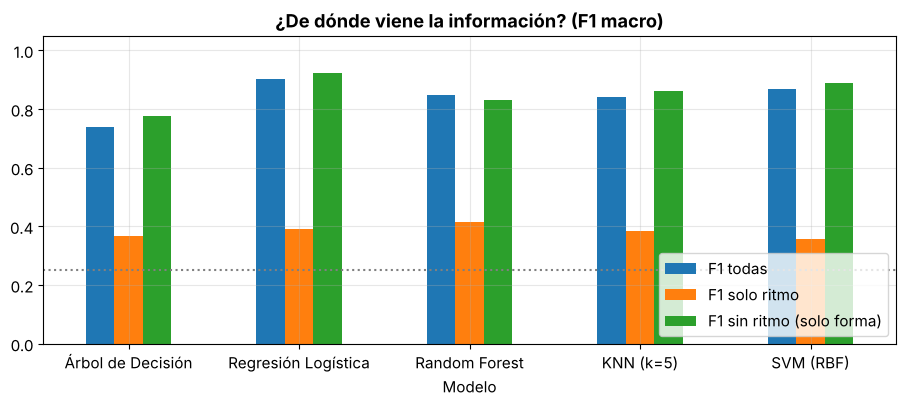

Random Forest (solo forma) — latidos mezclados al azar (con fuga): F1 = 0.877
Random Forest (solo forma) — validación por bloques (correcta)    : F1 = 0.832


In [21]:
RITMO = ["RR_prev_ms", "RR_next_ms", "FC_lpm"]
SIN_RITMO = [c for c in CARACTERISTICAS if c not in RITMO]
res_sin = comparar_modelos(tabla, SIN_RITMO)
comparacion = pd.DataFrame({"F1 todas": resultados["F1 macro"],
                            "F1 solo ritmo": comparar_modelos(tabla, RITMO)["F1 macro"],
                            "F1 sin ritmo (solo forma)": res_sin["F1 macro"]})
display(comparacion.round(3))
ax = comparacion.plot.bar(figsize=(11, 4), rot=0, ylim=(0, 1.05), title="¿De dónde viene la información? (F1 macro)")
ax.axhline(1/len(CLASES), color="gray", ls=":"); ax.legend(loc="lower right"); plt.show()

# La "trampa": ¿qué habría pasado si mezclábamos los latidos al azar?
azar = cross_validate(nuevo_modelo("Random Forest"), tabla[SIN_RITMO].to_numpy(), y, scoring="f1_macro",
                      cv=StratifiedKFold(n_pliegues, shuffle=True, random_state=0))["test_score"].mean()
print(f"Random Forest (solo forma) — latidos mezclados al azar (con fuga): F1 = {azar:.3f}")
print(f"Random Forest (solo forma) — validación por bloques (correcta)    : F1 = {res_sin.loc['Random Forest', 'F1 macro']:.3f}")

### ✍️ Pregunta B.4
1. ¿Qué clasificador obtuvo el mejor F1? ¿Coincide con el artículo base (Random Forest)? ¿La diferencia con el segundo es mayor que la variación entre pliegues?
2. En la matriz de confusión, ¿qué condiciones se confunden más entre sí? Relaciónalo con la Pregunta B.3.
3. Al **quitar el ritmo**, ¿cuánto cambió el F1? ¿Qué te dice eso sobre la forma del latido en tus condiciones?
4. ¿Hubo diferencia entre mezclar al azar y validar por bloques? ¿Por qué el valor "al azar" no es confiable?

✍️ **Respuesta:**

1. El mejor F1 macro fue el de **Regresión Logística (0.904 ± 0.040)**, seguido de SVM (0.868 ± 0.038). Random Forest quedó en 0.850 ± 0.066, así que no coincide con el artículo base. La diferencia entre LR y SVM (0.036) es menor que la variación entre pliegues (~0.04), así que no podemos afirmar que uno sea mejor que el otro. Con solo 154 latidos y 3 pliegues, es razonable que un modelo lineal funcione igual o mejor que RF.
2. Las que más se confunden son **basal e hiperventilación**: 6 latidos basales se clasificaron como hiperventilación y 5 de hiperventilación como basal. La hipoventilación (38/39) y la aeróbica (36/37) casi no tienen errores. Coincide con la Pregunta B.3, donde basal e hiperventilación eran las más parecidas.
3. Al quitar el ritmo, el F1 no bajó, incluso subió un poco en varios modelos (LR 0.904 → 0.923, SVM 0.868 → 0.888, RF 0.850 → 0.832). En cambio, con solo el ritmo el F1 queda entre 0.36 y 0.42, apenas por encima del azar (0.25), porque la FC solo diferencia bien a la aeróbica. Entonces, en nuestros datos la información está en la forma del latido y no solo en la FC.
4. Sí. Con los latidos mezclados al azar, RF obtuvo F1 = 0.877; con la validación por bloques, 0.832. El valor "al azar" es más optimista porque latidos consecutivos son casi copias: el modelo se evalúa con latidos casi iguales a los que vio al entrenar (fuga de datos), así que no mide cómo funcionaría con datos realmente nuevos.

<a id="B8"></a>
## B.8 Conclusiones de la Parte B

| Etapa | Idea clave |
|---|---|
| Filtrado | 0.5–40 Hz + notch 60 Hz: quita la deriva y la red eléctrica sin deformar P-QRS-T |
| Detección (Pan-Tompkins) | Resaltar lo **rápido y grande** (QRS) y apagar lo lento (P, T): filtro → derivada → cuadrado → integración → umbral |
| Segmentación | Ventana −200/+400 ms alrededor de R y control de calidad por RR |
| Características | 5 familias, 24 números por latido: ritmo, morfología, estadísticas, HOS y frecuencia (FFT + wavelet) |
| Clasificación | Comparar DT, LR, RF, KNN y SVM **validando por bloques** para no hacer trampa |

### ⚠️ Limitaciones para tener en cuenta
- **Un solo participante y un archivo de ~30 s por condición:** el modelo aprende las condiciones de *esta* persona en *esta* sesión. Parte de lo que distingue a dos archivos puede ser el propio registro (contacto de electrodos, minutos de diferencia), no solo la fisiología.
- Las medidas morfológicas son **aproximadas** (ventanas fijas).
- En el artículo base las clases son **tipos de latido** (normales y patológicos) de muchos pacientes. Aquí son **condiciones fisiológicas** de un mismo sujeto: el procedimiento es el mismo, pero la pregunta es distinta.

[⬆️ Volver al índice](#indice)

---
<a id="cuestionario"></a>
# 📝 Cuestionario final: experimenta con tus datos

La función `experimento(...)` repite **toda la Parte B** (detección → latidos → características → clasificación) con los parámetros que elijas, y muestra un resumen. Úsala para responder las 5 preguntas. Cada pregunta indica qué ejecutar.

```python
experimento(derivacion="D1",          # "D1", "D2" o "D3"
            condiciones=None,         # None = todas, o una lista: ["basal", "aerobica"]
            invertir="auto",          # "auto", True o False
            factor_umbral=0.3,        # sensibilidad del detector de picos R
            columnas=None)            # None = 24 características; RITMO; SIN_RITMO; o tu propia lista
```

In [22]:
def experimento(derivacion="D1", condiciones=None, invertir="auto", factor_umbral=0.3, columnas=None,
                mostrar=True):
    sel = inventario[inventario.derivacion == derivacion]
    conds = [c for c in ORDEN_CONDICIONES if c in sel.condicion.values and (condiciones is None or c in condiciones)]
    regs = {c: sel[sel.condicion == c].archivo.tolist() for c in conds}
    if len(conds) < 2:
        print(f"⚠️ La derivación {derivacion} no tiene al menos 2 condiciones disponibles.")
        return None, None, None
    resumen = []
    for c, archivos in regs.items():
        for a in archivos:
            r_ = preparar_registro(senales[a], invertir=invertir, factor_umbral=factor_umbral)
            resumen.append({"condición": c, "archivo": a, "invertida": r_["invertida"],
                            "detectados": len(r_["picos_R"]), "válidos": len(r_["validos"]),
                            "% RR anómalos": round(100 * r_["anomalo"].mean(), 1)})
    lat, inf = segmentar(regs)
    tab = construir_tabla(lat, inf)
    cols = CARACTERISTICAS if columnas is None else columnas
    try:
        res = comparar_modelos(tab, cols)
    except (AssertionError, ValueError) as e:
        res = None
        print(f"⚠️ No se pudo clasificar con estos parámetros: {e}")
    if mostrar:
        print(f"▶ {derivacion} | condiciones: {conds} | invertir={invertir} | factor_umbral={factor_umbral} | "
              f"{len(cols)} características | azar = {1/len(conds):.2f}")
        display(pd.DataFrame(resumen))
        if res is not None:
            display(res[["F1 macro", "± F1"]].T.round(3))
    # Devolvemos los registros de la derivación elegida a su configuración original
    for a in sel.archivo:
        preparar_registro(senales[a], invertir="auto")
    for a in seleccion.archivo:
        preparar_registro(senales[a], invertir=INVERTIR)
    return res, tab, pd.DataFrame(resumen)

print("✅ Función experimento() lista.")

✅ Función experimento() lista.


### Pregunta 1 — ¿Qué derivación funciona mejor?
Ejecuta `experimento("D1")`, `experimento("D2")` y `experimento("D3")`. ¿Con qué derivación y qué modelo obtienes el mejor F1? ¿Coincide con la calidad que viste en la Parte A?

### Pregunta 2 — ¿Importa la polaridad?
En **D2**, compara `experimento("D2", invertir="auto")` con `experimento("D2", invertir=False)`. ¿Cambia el número de latidos detectados? Usando la tabla devuelta (`res, tab, resumen = experimento(...)`), compara el promedio de `amp_R` y `amp_S`. ¿Qué onda está midiendo realmente `amp_R` en cada caso? ¿Cambia el F1?

### Pregunta 3 — Pares de condiciones: ¿cuál es más difícil de distinguir?
En tu derivación, clasifica solo **dos** condiciones: `["basal", "aerobica"]` y `["basal", "hiperventilacion"]`. Para cada par, compara todas las características con `columnas=RITMO`. ¿Qué par es más difícil y por qué?

### Pregunta 4 — Sensibilidad del detector
Cambia `factor_umbral` a **0.1**, **0.3** y **0.7**. ¿Cómo cambian los latidos detectados y válidos en el archivo con más problemas de calidad (Parte A)? ¿Qué valor elegirías y por qué?

### Pregunta 5 — ¿Cuántas características necesitamos?
Usa solo las **5 características más importantes** del Random Forest (gráfico de B.7), por ejemplo `columnas=imp.tail(5).index.tolist()`. ¿El F1 baja mucho respecto a las 24? ¿Qué ventaja práctica tendría usar menos características?

✍️ **Respuestas:** están al final de los experimentos (celdas de abajo).

In [23]:
# Pregunta 1: derivaciones disponibles (solo tenemos D2)
for d in ["D1", "D2", "D3"]:
    res_d, _, _ = experimento(d)

⚠️ La derivación D1 no tiene al menos 2 condiciones disponibles.


▶ D2 | condiciones: ['basal', 'hiperventilacion', 'hipoventilacion', 'aerobica'] | invertir=auto | factor_umbral=0.3 | 24 características | azar = 0.25


,condición,archivo,invertida,detectados,válidos,% RR anómalos
0,basal,d2reposo.txt,False,42,40,0.0
1,hiperventilacion,hiperventilacion_d2.txt,False,40,38,0.0
2,hipoventilacion,hipoventilacion_d2.txt,False,41,39,0.0
3,aerobica,d2_act_fisica.txt,False,39,37,0.0


Modelo,Árbol de Decisión,Regresión Logística,Random Forest,KNN (k=5),SVM (RBF)
F1 macro,0.738,0.904,0.850,0.842,0.868
± F1,0.051,0.040,0.066,0.014,0.038


⚠️ La derivación D3 no tiene al menos 2 condiciones disponibles.


In [24]:
# Pregunta 2: polaridad en D2
res_auto, tab_auto, resu_auto = experimento("D2", invertir="auto")
res_noinv, tab_noinv, resu_noinv = experimento("D2", invertir=False)
res_inv, tab_inv, resu_inv = experimento("D2", invertir=True)
for nom, t_ in [("auto", tab_auto), ("invertir=False", tab_noinv), ("invertir=True", tab_inv)]:
    print(f"{nom:15s} → promedio amp_R = {t_['amp_R'].mean():.3f} mV | promedio amp_S = {t_['amp_S'].mean():.3f} mV")

▶ D2 | condiciones: ['basal', 'hiperventilacion', 'hipoventilacion', 'aerobica'] | invertir=auto | factor_umbral=0.3 | 24 características | azar = 0.25


,condición,archivo,invertida,detectados,válidos,% RR anómalos
0,basal,d2reposo.txt,False,42,40,0.0
1,hiperventilacion,hiperventilacion_d2.txt,False,40,38,0.0
2,hipoventilacion,hipoventilacion_d2.txt,False,41,39,0.0
3,aerobica,d2_act_fisica.txt,False,39,37,0.0


Modelo,Árbol de Decisión,Regresión Logística,Random Forest,KNN (k=5),SVM (RBF)
F1 macro,0.738,0.904,0.850,0.842,0.868
± F1,0.051,0.040,0.066,0.014,0.038


▶ D2 | condiciones: ['basal', 'hiperventilacion', 'hipoventilacion', 'aerobica'] | invertir=False | factor_umbral=0.3 | 24 características | azar = 0.25


,condición,archivo,invertida,detectados,válidos,% RR anómalos
0,basal,d2reposo.txt,False,42,40,0.0
1,hiperventilacion,hiperventilacion_d2.txt,False,40,38,0.0
2,hipoventilacion,hipoventilacion_d2.txt,False,41,39,0.0
3,aerobica,d2_act_fisica.txt,False,39,37,0.0


Modelo,Árbol de Decisión,Regresión Logística,Random Forest,KNN (k=5),SVM (RBF)
F1 macro,0.738,0.904,0.850,0.842,0.868
± F1,0.051,0.040,0.066,0.014,0.038


▶ D2 | condiciones: ['basal', 'hiperventilacion', 'hipoventilacion', 'aerobica'] | invertir=True | factor_umbral=0.3 | 24 características | azar = 0.25


,condición,archivo,invertida,detectados,válidos,% RR anómalos
0,basal,d2reposo.txt,True,42,40,0.0
1,hiperventilacion,hiperventilacion_d2.txt,True,40,38,0.0
2,hipoventilacion,hipoventilacion_d2.txt,True,41,39,0.0
3,aerobica,d2_act_fisica.txt,True,39,37,0.0


Modelo,Árbol de Decisión,Regresión Logística,Random Forest,KNN (k=5),SVM (RBF)
F1 macro,0.715,0.858,0.854,0.835,0.852
± F1,0.074,0.035,0.041,0.018,0.041


auto            → promedio amp_R = 1.689 mV | promedio amp_S = -0.543 mV
invertir=False  → promedio amp_R = 1.689 mV | promedio amp_S = -0.543 mV
invertir=True   → promedio amp_R = 0.515 mV | promedio amp_S = -0.116 mV


In [25]:
# Pregunta 3: pares de condiciones (todas las características vs solo ritmo)
filas_p3 = []
for par in [["basal", "aerobica"], ["basal", "hiperventilacion"]]:
    r_todas, _, _ = experimento("D2", condiciones=par, mostrar=False)
    r_ritmo, _, _ = experimento("D2", condiciones=par, columnas=RITMO, mostrar=False)
    for m in r_todas.index:
        filas_p3.append({"par": " vs ".join(par), "modelo": m,
                         "F1 todas": r_todas.loc[m, "F1 macro"], "F1 solo ritmo": r_ritmo.loc[m, "F1 macro"]})
p3 = pd.DataFrame(filas_p3)
display(p3.pivot(index="modelo", columns="par", values=["F1 todas", "F1 solo ritmo"]).round(3))

F1 todas                            \
par                 basal vs aerobica basal vs hiperventilacion   
modelo                                                            
KNN (k=5)                       0.936                     0.715   
Random Forest                   0.979                     0.672   
Regresión Logística             0.959                     0.871   
SVM (RBF)                       0.947                     0.762   
Árbol de Decisión               0.876                     0.577   

                        F1 solo ritmo                            
par                 basal vs aerobica basal vs hiperventilacion  
modelo                                                           
KNN (k=5)                       0.869                     0.312  
Random Forest                   0.841                     0.406  
Regresión Logística             0.876                     0.300  
SVM (RBF)                       0.892                     0.201  
Árbol de Decisión               0.841                     0.289

In [26]:
# Pregunta 4: sensibilidad del detector
filas_p4 = []
for fu in [0.1, 0.3, 0.7]:
    res_fu, _, resu_fu = experimento("D2", factor_umbral=fu, mostrar=False)
    for _, f_ in resu_fu.iterrows():
        filas_p4.append({"factor_umbral": fu, "condición": f_["condición"], "detectados": f_["detectados"],
                         "válidos": f_["válidos"], "% RR anómalos": f_["% RR anómalos"]})
    if res_fu is not None:
        print(f"factor_umbral={fu}: F1 macro Random Forest = {res_fu.loc['Random Forest', 'F1 macro']:.3f}")
display(pd.DataFrame(filas_p4).pivot(index="condición", columns="factor_umbral",
                                     values=["detectados", "válidos", "% RR anómalos"]).reindex(CLASES))

factor_umbral=0.1: F1 macro Random Forest = 0.850


factor_umbral=0.3: F1 macro Random Forest = 0.850


factor_umbral=0.7: F1 macro Random Forest = 0.850


detectados             válidos             % RR anómalos  \
factor_umbral           0.1   0.3   0.7     0.1   0.3   0.7           0.1   
condición                                                                   
basal                  42.0  42.0  42.0    40.0  40.0  40.0           0.0   
hiperventilacion       40.0  40.0  40.0    38.0  38.0  38.0           0.0   
hipoventilacion        41.0  41.0  41.0    39.0  39.0  39.0           0.0   
aerobica               39.0  39.0  39.0    37.0  37.0  37.0           0.0   

                            
factor_umbral     0.3  0.7  
condición                   
basal             0.0  0.0  
hiperventilacion  0.0  0.0  
hipoventilacion   0.0  0.0  
aerobica          0.0  0.0

In [27]:
# Pregunta 5: solo las 5 características más importantes del Random Forest
top5 = imp.tail(5).index.tolist()
print("Top 5:", top5)
res_top5, _, _ = experimento("D2", columnas=top5, mostrar=False)
display(pd.DataFrame({"F1 (24 caract.)": resultados["F1 macro"], "F1 (top 5)": res_top5["F1 macro"]}).round(3))

Top 5: ['wav_E_cA6', 'amp_R', 'asimetria', 'amp_S', 'potencia_0.5_40']


,F1 (24 caract.),F1 (top 5)
Modelo,,
Árbol de Decisión,0.738,0.775
Regresión Logística,0.904,0.813
Random Forest,0.850,0.807
KNN (k=5),0.842,0.781
SVM (RBF),0.868,0.817


### ✍️ Respuestas del cuestionario

**Pregunta 1.** Solo registramos D2, así que `experimento("D1")` y `experimento("D3")` no se pueden ejecutar (no hay archivos). En D2 el mejor modelo fue Regresión Logística con F1 = 0.904 ± 0.040. Coincide con la Parte A: D2 no tuvo RR anómalos y la detección fue correcta en todos los archivos. Lo único que preocupaba era la saturación del R, y no impidió obtener un buen F1.

**Pregunta 2.** En D2, `invertir="auto"` y `invertir=False` dan exactamente lo mismo, porque el QRS ya es positivo y no se invierte nada. Al forzar la inversión (`invertir=True`), el número de latidos detectados no cambia (42, 40, 41 y 39), porque Pan-Tompkins eleva la derivada al cuadrado y no le importa el signo. Lo que cambia es el significado de las medidas: el promedio de `amp_R` pasa de 1.689 mV a 0.515 mV y `amp_S` de −0.543 a −0.116 mV. Con la señal invertida, el "R" que se mide es en realidad la onda S invertida, y lo que queda como "S" ya no corresponde a esa onda. El F1 casi no cambia en RF (0.850 → 0.854), pero sí baja en LR (0.904 → 0.858). Por eso es mejor no invertir en D2, para que las medidas conserven su nombre anatómico.

**Pregunta 3.** El par **basal vs. hiperventilación** es mucho más difícil. Con todas las características obtiene F1 entre 0.58 (DT) y 0.87 (LR), y con solo ritmo entre 0.20 y 0.41, por debajo del azar para 2 clases (0.5). Basal vs. aeróbica se separa casi perfecto: F1 = 0.88–0.98 con todas las características y 0.84–0.89 solo con el ritmo. La razón es que la aeróbica tiene una FC mucho mayor (98 vs. 80 lpm) y una forma distinta (T más alta, S más profunda). En cambio, basal e hiperventilación tienen casi la misma FC (80 vs. 77.6 lpm) y latidos promedio casi superpuestos.

**Pregunta 4.** Con `factor_umbral` = 0.1, 0.3 y 0.7, los latidos detectados y válidos no cambian en ningún archivo (42/40, 40/38, 41/39 y 39/37), los RR anómalos siguen en 0 % y el F1 de RF se mantiene en 0.850. Esto pasa porque nuestras señales son limpias y el QRS es muy grande frente a P y T. Después de la integración, las "jorobas" del QRS están muy por encima de todo lo demás, y el periodo refractario de 250 ms evita detecciones dobles. Ni siquiera el archivo aeróbico, que tenía más saturación y la FC más alta, cambió. Elegiríamos **0.3**, porque está en el medio: deja margen para no perder latidos pequeños (con umbral alto) y para no detectar ruido u ondas T grandes (con umbral bajo) en registros con más ruido que los nuestros.

**Pregunta 5.** Las 5 características más importantes del RF fueron potencia_0.5_40, amp_S, asimetría, amp_R y wav_E_cA6. Con solo ellas el F1 baja un poco en casi todos los modelos (LR 0.904 → 0.813, SVM 0.868 → 0.817, RF 0.850 → 0.807, KNN 0.842 → 0.781) y el Árbol de Decisión incluso mejora (0.738 → 0.775). Es una pérdida de ~0.04–0.09 usando 5 características en lugar de 24. La ventaja práctica es que el cálculo es más rápido (útil en tiempo real o en un dispositivo portátil como el BITalino), hay menos riesgo de sobreajuste cuando hay pocos latidos (solo tenemos 154) y el modelo es más fácil de interpretar.

### Conclusiones
- El pipeline funcionó bien con nuestros registros de D2: Pan-Tompkins detectó todos los latidos sin RR anómalos y obtuvimos 154 latidos válidos.
- La condición aeróbica es la más fácil de reconocer (FC alta, T más alta y más cercana al R, S más profunda). Basal e hiperventilación son las que más se confunden.
- La forma del latido aporta más información que la FC: sin las características de ritmo el F1 se mantiene, y solo con ritmo cae cerca del azar.
- Limitaciones: hay un solo participante y una sola derivación, cada condición es un único registro de ~30 s (24 s en la aeróbica) y los cuatro archivos tienen la punta del R saturada, así que `amp_R` está subestimada. Para una próxima vez, convendría revisar la saturación durante la adquisición (por ejemplo, reubicando los electrodos) y grabar más tiempo por condición.


---
<a id="entregables"></a>
# 📦 Entregables y referencias

### Entregables
1. Este cuaderno ejecutado **con tus registros**, con todas las preguntas ✍️ respondidas.
2. El cuestionario final con tus experimentos.
3. El archivo `caracteristicas_ecg.csv` (se genera en la celda siguiente).

### Referencias
1. T. Subba y T. Chingtham, "Comparative Analysis of Machine Learning Algorithms With Advanced Feature Extraction for ECG Signal Classification", *IEEE Access*, 2024. doi: 10.1109/ACCESS.2024.3387041
2. J. Pan y W. J. Tompkins, "A Real-Time QRS Detection Algorithm", *IEEE Trans. Biomed. Eng.*, vol. BME-32, no. 3, pp. 230–236, 1985.
3. PLUX Wireless Biosignals, *BITalino (r)evolution — ECG Sensor Datasheet* (fórmula de conversión).
4. L. Sörnmo y P. Laguna, *Bioelectrical Signal Processing in Cardiac and Neurological Applications*, Elsevier, 2005.

[⬆️ Volver al índice](#indice)

In [28]:
tabla.to_csv("caracteristicas_ecg.csv", index=False)
print("✅ Archivo generado: caracteristicas_ecg.csv", tabla.shape)
try:
    from google.colab import files
    files.download("caracteristicas_ecg.csv")
except ImportError:
    pass

✅ Archivo generado: caracteristicas_ecg.csv (154, 27)
